# Trabajo Práctico: Predicción de precios de casas

**Aprendizaje Automático 1**, Tecnicatura en Inteligencia Artificial
Facultad de Ciencias Exactas, Ingeniería y Agrimensura (UNR). 2026, cuatrimestre 2

**Integrantes:** Sofia Grando, Amanda Tardugno, Lucas Díaz y Facundo Ferreira

La idea es predecir `MEDV`, el valor mediano de las viviendas de cada barrio de Boston en
miles de dólares, usando las otras 13 variables. Como lo que queremos predecir es un número
y no una categoría, es un problema de regresión.

Vamos en este orden: primero el análisis descriptivo y la preparación de los datos, después
la regresión lineal múltiple por los distintos métodos (mínimos cuadrados, gradiente
descendente y regularización), después la búsqueda de hiperparámetros y al final la
comparación de todos los modelos.

## Configuración del entorno

In [1]:
# Las bibliotecas que usamos en todo el notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Estilo de los gráficos y semilla fija, para que todo salga igual cada vez que corremos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)

# Análisis descriptivo y preprocesamiento

Esta primera parte es el ítem 3: entender las variables, ver qué hacemos con los faltantes,
graficar, mirar correlaciones, escalar y dividir el conjunto. Todo lo que viene después
depende de las decisiones que tomemos acá.

## Carga e inspección estructural

In [3]:
# El csv está en la misma carpeta que el notebook
df = pd.read_csv("house-prices-tp.csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.07151,0.0,4.49,0.0,0.449,6.121,56.8,3.7476,3.0,247.0,18.5,395.15,8.44,22.2
1,0.08265,0.0,13.92,0.0,0.437,6.127,18.4,5.5027,4.0,289.0,16.0,396.90,8.58,23.9
2,0.12816,12.5,6.07,0.0,0.409,5.885,33.0,6.4980,4.0,345.0,18.9,396.90,8.79,20.9
3,0.08873,21.0,5.64,0.0,0.439,5.963,45.7,6.8147,4.0,243.0,16.8,395.56,13.45,19.7
4,0.11432,0.0,8.56,0.0,0.520,6.781,71.3,2.8561,5.0,384.0,20.9,395.58,7.67,26.5


In [4]:
# Dimensiones y tipo de dato de cada variable
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.dtypes.to_frame("tipo")

Filas: 556  |  Columnas: 14


,tipo
CRIM,float64
ZN,float64
INDUS,float64
CHAS,float64
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,float64
TAX,float64


In [5]:
# Chequeamos que no haya filas repetidas, que le darían peso de más a esos barrios
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

Filas duplicadas exactas: 0


### Las variables

Según el enunciado, las 13 características de entrada y la variable a predecir son:

| Variable | Significado |
|---|---|
| `CRIM` | Tasa de criminalidad per cápita por ciudad |
| `ZN` | Proporción de terrenos residenciales zonificados para lotes de más de 25.000 pies² |
| `INDUS` | Proporción de acres de negocios no minoristas por ciudad |
| `CHAS` | Variable *dummy* del río Charles (1 si el tramo limita con el río, 0 si no) |
| `NOX` | Concentración de óxidos de nitrógeno (partes por 10 millones) |
| `RM` | Número promedio de habitaciones por vivienda |
| `AGE` | Proporción de unidades ocupadas por sus propietarios construidas antes de 1940 |
| `DIS` | Distancias ponderadas a cinco centros de empleo de Boston |
| `RAD` | Índice de accesibilidad a las autopistas radiales |
| `TAX` | Tasa de impuesto sobre la propiedad a valor completo por cada $10.000 |
| `PTRATIO` | Proporción alumno-maestro por ciudad |
| `B` | Resultado de la ecuación B = 1000(Bk − 0,63)², con Bk la proporción de negros por ciudad |
| `LSTAT` | Porcentaje de población de menor estatus socioeconómico |
| **`MEDV`** | **Valor mediano de las viviendas, en miles de dólares, variable a predecir** |

Todas las columnas entraron como numéricas, que es lo que corresponde: no hay texto ni
categorías nominales para codificar. Dos necesitan una aclaración:

- `CHAS` es una *dummy* que ya viene como 0/1, así que no hay que hacerle nada.
- `RAD` es un índice de accesibilidad. En la documentación original es entero de 1 a 24,
  pero en este archivo aparecen además 22 valores con decimales (1,307; 4,528; etc.), que no
  corresponden a ningún nivel del índice. Los miramos de cerca más adelante, cuando tratemos
  los datos faltantes. Sea como sea, es una variable **ordinal** (más alto = más
  accesibilidad), así que la dejamos numérica para no perder ese orden.

Aparte, `B` merece un comentario. Es una variable armada a partir de la composición racial
del barrio, y es la más cuestionada del dataset, tanto por lo que codifica como por la
transformación cuadrática que la deja imposible de interpretar. La dejamos porque el
enunciado la lista como característica de entrada, pero hay que tenerlo presente cuando
miremos los coeficientes.

## Análisis descriptivo

In [6]:
# Medidas de tendencia central y dispersión de todas las variables
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CRIM,533.0,5.85,13.83,0.01,0.08,0.32,4.87,88.98
ZN,534.0,13.20,24.90,0.00,0.00,0.00,20.00,100.00
INDUS,541.0,11.22,6.94,0.46,5.13,9.69,18.10,27.74
CHAS,533.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00
NOX,532.0,0.56,0.12,0.38,0.45,0.54,0.64,0.87
RM,535.0,6.29,0.78,3.56,5.88,6.21,6.64,8.78
AGE,532.0,67.63,28.46,2.90,42.28,76.50,93.82,100.00
DIS,541.0,3.94,2.26,1.13,2.11,3.34,5.40,12.13
RAD,528.0,9.70,8.68,1.00,4.00,5.00,23.63,24.00
TAX,538.0,409.58,167.69,187.00,279.00,335.00,666.00,711.00


In [7]:
# El sesgo mide la asimetría: lejos de 0 quiere decir que hay una cola larga
df.skew().sort_values(ascending=False).to_frame("sesgo").round(2)

,sesgo
CRIM,3.75
CHAS,2.87
ZN,1.96
DIS,1.08
MEDV,1.06
RAD,0.95
LSTAT,0.95
NOX,0.69
TAX,0.63
RM,0.37


### Cada variable, una por una

El enunciado pide describir cada variable con su comportamiento y su rango, así que las
recorremos agrupadas por lo que miden, que es como se entienden mejor.

**Las del entorno socioeconómico**

- `LSTAT` (1,73 a 37,97, mediana 11,46) es el porcentaje de población de menor estatus
  socioeconómico. Se reparte de forma bastante continua, con sesgo positivo suave (0,95):
  hay más barrios acomodados que muy pobres, pero no hay saltos.
- `CRIM` (0,01 a 88,98, mediana 0,32) es la más extrema de todas, con sesgo 3,75. La mediana
  en 0,32 contra una media de 5,85 muestra el problema: la mitad de los barrios tiene
  criminalidad casi nula y un puñado se dispara dos órdenes de magnitud.
- `B` (0,32 a 396,90, mediana 390,82) es la única con sesgo negativo fuerte (−2,40), y se
  entiende por cómo está construida: al ser una parábola centrada en 0,63, casi todos los
  barrios terminan apilados cerca del máximo.

**Las de la vivienda**

- `RM` (3,56 a 8,78, mediana 6,21) es el promedio de habitaciones. Es la más simétrica del
  conjunto (sesgo 0,37) y la que más se parece a una normal.
- `AGE` (2,90 a 100, mediana 76,50) es la proporción de viviendas anteriores a 1940. Tiene
  sesgo negativo (−0,55) y se amontona contra el 100: en la mayoría de los barrios el parque
  edilicio es viejo.
- `ZN` (0 a 100, mediana 0) es la proporción de terreno zonificado para lotes grandes. En
  372 de los 534 barrios observados vale exactamente 0, así que más que una variable
  continua se comporta como "tiene o no tiene lotes grandes" y, cuando tiene, cuántos.

**Las del entorno urbano e industrial**

- `INDUS` (0,46 a 27,74, mediana 9,69) es la proporción de suelo industrial, y es la más
  pareja de todo el conjunto (sesgo 0,30).
- `NOX` (0,38 a 0,87, mediana 0,54) mide contaminación. Rango chico en valor absoluto, pero
  el máximo más que duplica al mínimo.
- `DIS` (1,13 a 12,13, mediana 3,34) es la distancia a los centros de empleo, con sesgo 1,08:
  la mayoría de los barrios está cerca y unos pocos quedan lejos.
- `CHAS` (0 o 1) indica si el barrio linda con el río. Sólo 48 de 533 valen 1, apenas un 9%,
  así que es una variable muy desbalanceada.

**Las institucionales**

- `RAD` (1 a 24, mediana 5) es el índice de accesibilidad a autopistas. No se reparte
  continuo: 132 barrios valen exactamente 24 y el resto se concentra entre 1 y 8. Son dos
  grupos separados más que una escala gradual.
- `TAX` (187 a 711, mediana 335) es la tasa impositiva, y tiene la misma estructura partida:
  143 barrios superan los 600. No es casualidad que se parezca a `RAD`, y lo vamos a ver en
  la correlación.
- `PTRATIO` (12,60 a 22, mediana 19) es la relación alumno-maestro, con sesgo negativo
  (−0,79) y concentrada en la parte alta del rango.

**La variable a predecir**

- `MEDV` (5 a 50, mediana 21,20) es el precio en miles de dólares, con sesgo positivo (1,06).
  El máximo exacto en 50 es lo que miramos a continuación.

### Lectura del descriptivo

Lo primero que salta es que las escalas no tienen nada que ver entre sí. `TAX` va de 187 a
711 y `B` llega a 396,9, mientras que `NOX` se mueve entre 0,38 y 0,87 y `CHAS` es 0 o 1.
A mínimos cuadrados esto no le molesta, pero al gradiente descendente sí (converge mal
cuando las escalas son dispares) y a la regularización todavía más, porque la penalización
mira el tamaño del coeficiente: sin escalar castigaría más a las variables de valores
chicos sólo por la unidad en la que están medidas. Por eso vamos a escalar antes de llegar
a esos modelos.

Varias distribuciones son bastante asimétricas. `CRIM` tiene mediana 0,32 pero máximo 88,98:
casi todos los barrios tienen criminalidad baja y unos pocos estiran la cola. Pasa algo
parecido con `ZN` (mediana 0) y con `CHAS` (apenas el 9% de los barrios linda con el río).
Hay que tenerlo en cuenta cuando decidamos qué hacer con los outliers, porque en
estas variables un valor extremo no es necesariamente un error de carga: puede ser un barrio
que realmente es así.

Y hay algo en `MEDV` que nos llamó la atención: llega justo hasta 50. Con mediana 21,2, que
el máximo sea un número tan redondo es raro. Si los valores altos se repartieran como en
cualquier variable continua, no habría motivo para que se corten exactamente ahí.

In [8]:
# Contamos cuántas viviendas caen justo en el máximo de la escala
tope = (df["MEDV"] == 50).sum()
print(f"Viviendas con MEDV = 50: {tope} ({tope / df['MEDV'].notna().sum():.1%} de las observadas)")

Viviendas con MEDV = 50: 16 (3.0% de las observadas)


Son 16 viviendas apiladas exactamente en 50 en vez de repartirse por encima. No es
casualidad de la muestra: es un tope que se puso al armar el dataset, donde todo lo que
valía más se anotó como 50.

Para el modelo esto significa que ahí el valor real no lo sabemos. Lo retomamos cuando
decidamos la limpieza, junto con los faltantes.

## Análisis y decisión sobre datos faltantes

In [9]:
# Cantidad y porcentaje de valores faltantes en cada variable
faltantes = df.isna().sum()
pd.DataFrame({"faltantes": faltantes,
              "% del total": (faltantes / len(df) * 100).round(1)})

,faltantes,% del total
CRIM,23,4.1
ZN,22,4.0
INDUS,15,2.7
CHAS,23,4.1
NOX,24,4.3
RM,21,3.8
AGE,24,4.3
DIS,15,2.7
RAD,28,5.0
TAX,18,3.2


In [10]:
# Cuántos valores le faltan a cada fila, para ver si los faltantes se concentran o no
por_fila = df.isna().sum(axis=1)
print(f"Celdas faltantes en total: {int(faltantes.sum())}")
print(f"Filas completas: {(por_fila == 0).sum()}  |  Filas con al menos un faltante: {(por_fila > 0).sum()}")
por_fila[por_fila > 0].value_counts().sort_index().to_frame("cantidad de filas").rename_axis("faltantes en la fila")

Celdas faltantes en total: 306
Filas completas: 506  |  Filas con al menos un faltante: 50


,cantidad de filas
faltantes en la fila,
1,5
2,3
3,11
4,3
5,3
6,2
7,5
8,4
9,4


### Diagnóstico

Los faltantes no están repartidos al azar:

- Las 306 celdas faltantes se concentran en apenas **50 filas**. Las otras 506 están
  completas, sin un solo valor ausente.
- Esas 50 filas están muy incompletas: en promedio les faltan 6 de sus 14 valores, y hay
  tres a las que les faltan 13 columnas y una a la que le faltan las 14.
- En 21 de ellas lo que falta es `MEDV`, que es justo lo que hay que predecir.

### Decisión

Eliminamos toda fila que tenga al menos un valor faltante. Quedan las 506 filas completas,
el 91% del original.

Podríamos imputar, pero imputar supone que la fila todavía tiene información suficiente
como para estimar lo que le falta, y acá no es el caso: les falta en promedio un valor de
cada dos y a varias casi todo. Lo que pusiéramos no describiría a ese barrio sino al método
de imputación que usemos, y entrenar con eso es meter ruido haciéndolo pasar por dato.

Las 21 filas sin `MEDV` las sacamos además por otro motivo, que vale aunque el resto de la
fila esté completa: `MEDV` es lo que el modelo tiene que aprender a predecir. Completarla
con una estimación nuestra sería entrenar al modelo contra algo que inventamos nosotros en
lugar de contra un dato real. Y si alguna de esas filas cayera en prueba, estaríamos
midiendo el error contra un valor inventado.

Perdemos 50 filas, un 9%. Es un costo aceptable: las 506 que quedan están completas,
así que de acá en adelante no arrastramos ningún valor ausente.

In [11]:
# Nos quedamos sólo con las filas completas
df_limpio = df.dropna().reset_index(drop=True)
print(f"Filas antes: {len(df)}  |  Filas después: {len(df_limpio)}  |  Eliminadas: {len(df) - len(df_limpio)}")
print(f"Valores faltantes restantes: {int(df_limpio.isna().sum().sum())}")

Filas antes: 556  |  Filas después: 506  |  Eliminadas: 50
Valores faltantes restantes: 0


### Decisión sobre el tope de `MEDV`

Sacamos también las viviendas con `MEDV` = 50, con el mismo criterio que acabamos de usar
para las filas sin `MEDV`.

Nos parece que son el mismo caso. Cuando `MEDV` viene vacío, no sabemos cuánto vale esa
vivienda. Cuando `MEDV` viene en 50 por el tope, tampoco: sabemos que vale 50 o más, pero no
cuánto. La única diferencia es que en un caso el dato ausente quedó como vacío y en el otro
quedó disfrazado de número. Si el primero nos alcanza para descartar la fila, el segundo
también.

Hay además un motivo práctico. Entrenar con esas filas es pedirle al modelo que ajuste sus
pesos para acertarle a un valor que sabemos que es falso, y eso le tira las predicciones de
todo el segmento caro para abajo. Y evaluar con ellas es peor todavía, porque estaríamos
midiendo el error contra un número inventado y descontándole puntos al modelo por no
acertarle. Por eso las sacamos de los tres conjuntos y no sólo de entrenamiento.

Las sacamos antes de dividir, igual que las filas incompletas y por la misma razón: es un
filtro por una condición fija, no estima ningún parámetro a partir de los datos, así que no
pasa información de un conjunto a otro.

Eso sí, el costo hay que decirlo: de acá en adelante el modelo describe viviendas de menos
de 50 mil dólares, y ni se entrena ni se evalúa sobre el segmento más caro. No sirve para
tasar una casa de lujo, y las métricas que reportemos no dicen nada sobre cómo andaría ahí.
Es una limitación del alcance, y la asumimos: preferimos un modelo que resuelve bien un
problema bien definido antes que uno que aparenta resolver un problema del que no tenemos
los datos.

In [12]:
# Quitamos las viviendas topeadas: su precio real es desconocido, igual que si faltara
topeadas = (df_limpio["MEDV"] == 50).sum()
df_modelo = df_limpio[df_limpio["MEDV"] != 50].reset_index(drop=True)
print(f"Filas antes: {len(df_limpio)}  |  Topeadas eliminadas: {topeadas}  |  Filas finales: {len(df_modelo)}")
print(f"Rango de MEDV: {df_modelo['MEDV'].min()} a {df_modelo['MEDV'].max()}  (mediana {df_modelo['MEDV'].median()})")

Filas antes: 506  |  Topeadas eliminadas: 16  |  Filas finales: 490
Rango de MEDV: 5.0 a 48.8  (mediana 20.9)


In [13]:
# Los decimales raros de RAD: revisamos si sobrevivieron a la limpieza
print("Valores distintos de RAD en el archivo original:", df["RAD"].nunique())
print("  de ellos, con decimales:", int((df["RAD"].dropna() % 1 != 0).sum()))
print("Valores distintos de RAD en el conjunto que vamos a usar:", sorted(df_modelo["RAD"].unique()))
print("  de ellos, con decimales:", int((df_modelo["RAD"] % 1 != 0).sum()))

Valores distintos de RAD en el archivo original: 31
  de ellos, con decimales: 22
Valores distintos de RAD en el conjunto que vamos a usar: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(24.0)]
  de ellos, con decimales: 0


Los 22 valores con decimales de `RAD` estaban **todos** en las filas que descartamos. En
las 490 que nos quedan, `RAD` toma nueve valores enteros: del 1 al 8 y el 24. Lo mismo pasa
con los decimales raros de `TAX`.

Es un detalle menor pero nos deja tranquilos con dos cosas. Una, que la variable se comporta
como el índice ordinal que dice ser, así que tratarla como numérica está bien. Y dos, que
esas 50 filas no sólo tenían faltantes: también tenían valores que no respetaban el formato
de la columna. Un argumento más para haberlas sacado en lugar de imputarlas.

## División en entrenamiento, validación y prueba

Dividimos acá, apenas terminada la limpieza y antes de escalar o de mirar correlaciones,
para no tener *data leakage*. Escalar no es una operación inocente: calcula la media y el
desvío de cada variable a partir de los datos. Si esos parámetros salen del conjunto
completo, los datos de prueba participan del preprocesamiento y dejan de ser datos nuevos
para el modelo. Lo que queda es una métrica de prueba optimista, que no dice nada sobre cómo
va a andar el modelo con datos que nunca vio. Por eso todo lo que *aprende* algo de los
datos se ajusta con entrenamiento y después se *aplica* a los otros dos.

Eliminar filas sí lo podíamos hacer antes, porque es un filtro por una condición fija y no
estima ningún parámetro.

Separamos tres conjuntos y no dos. El enunciado deja la validación como opcional pero nos
hace falta para los ítems 4 y 5:

- **Entrenamiento**: ajusta los coeficientes.
- **Validación**: sirve para elegir. El gradiente descendente necesita un paso de
  aprendizaje y una cantidad de épocas, y Ridge, Lasso y Elastic Net necesitan un `alpha`.
  Todas esas decisiones las tomamos comparando el error sobre validación.
- **Prueba**: queda guardado y no lo tocamos hasta la comparación final.

¿Por qué separar validación de prueba y no usar prueba para todo? Porque elegir
hiperparámetros mirando prueba lo convierte en parte del entrenamiento: nos quedaríamos con
la configuración que mejor le va a ese conjunto en particular, y la métrica final pasaría a
medir cuánto lo ajustamos a esas filas en vez de qué tan bien generaliza el modelo. Con
validación aparte, prueba se usa una sola vez y recién al final, y eso es lo que lo hace una
estimación honesta.

Lo hacemos en dos pasos, como en clase: primero apartamos el 20% de prueba y después, del
80% que queda, un 12,5%, que es el 10% del total. Quedan 70% / 10% / 20%. Fijamos
`random_state` en las dos divisiones para que la partición se pueda repetir.

In [14]:
# Separamos las características de la variable a predecir
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns="MEDV")
y = df_modelo["MEDV"]

In [15]:
# Primera división: apartamos prueba antes de cualquier transformación que aprenda algo de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

# Segunda división: del 80% restante separamos un 12,5%, que es el 10% del total, para validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.125, random_state=SEMILLA
)

In [16]:
# Tamaño de cada conjunto y su proporción sobre el total de filas usadas
pd.DataFrame({"filas": [len(X_train), len(X_val), len(X_test)],
              "% del total": [round(n / len(df_modelo) * 100, 1)
                              for n in (len(X_train), len(X_val), len(X_test))]},
             index=["entrenamiento", "validación", "prueba"])

,filas,% del total
entrenamiento,343,70.0
validación,49,10.0
prueba,98,20.0


## Visualización de los datos

Graficamos sólo entrenamiento. Mirar validación o prueba para tomar decisiones de modelado
es una forma medio disimulada de filtración, porque esas decisiones terminan metiendo
información que se supone que no tenemos.

In [17]:
# Juntamos X e y de entrenamiento en un solo DataFrame para poder graficar contra MEDV
train = X_train.copy()
train["MEDV"] = y_train

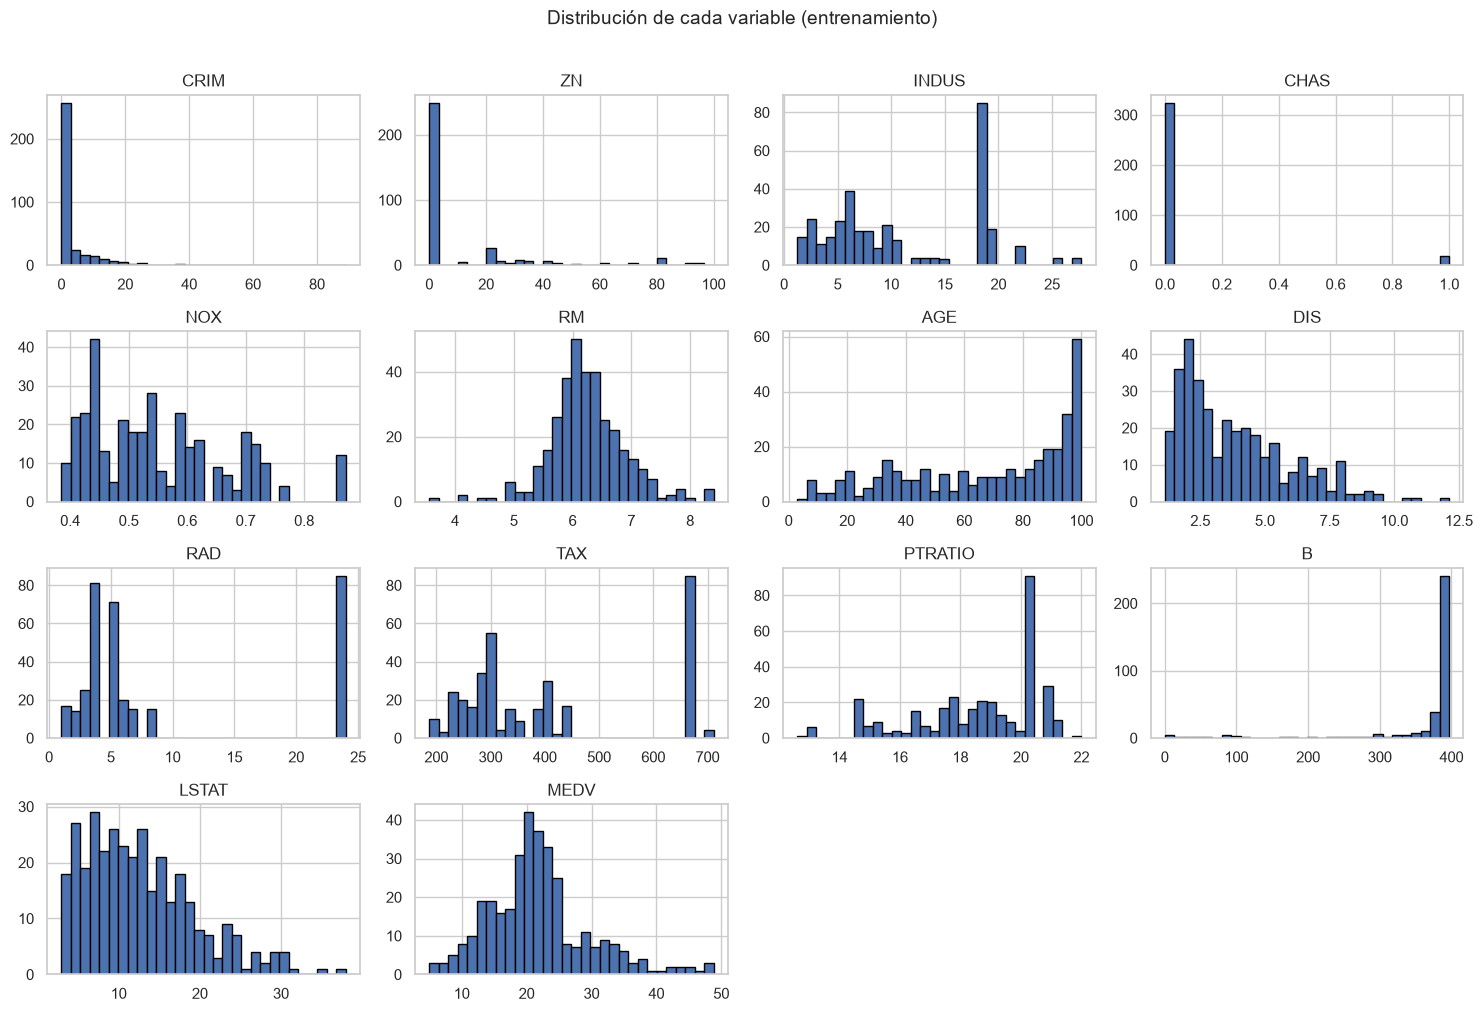

In [18]:
# Histogramas de todas las variables para ver la forma de cada distribución
train.hist(bins=30, figsize=(15, 10), edgecolor="black")
plt.suptitle("Distribución de cada variable (entrenamiento)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

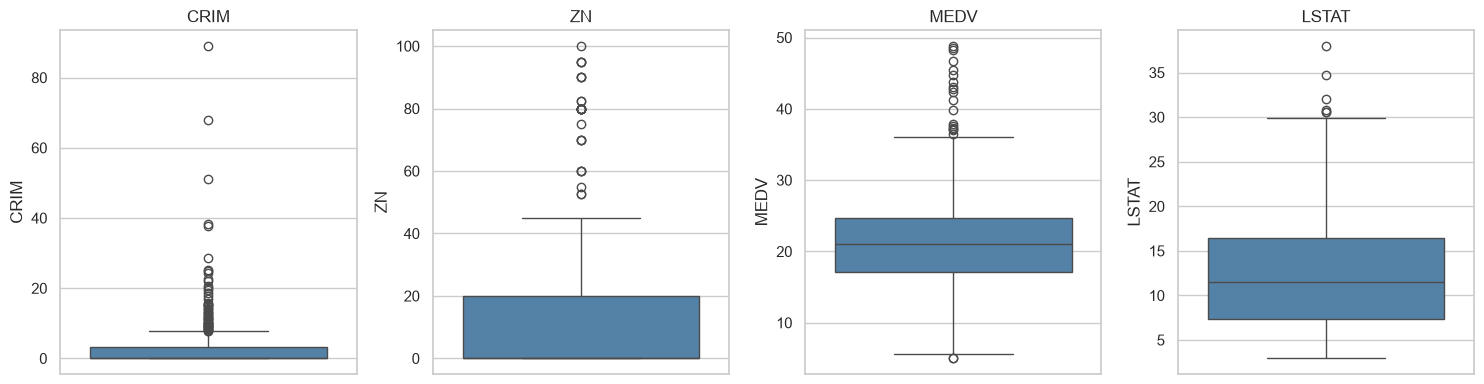

In [19]:
# Boxplots de las más asimétricas, para ver el tamaño de los valores atípicos
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["CRIM", "ZN", "MEDV", "LSTAT"]):
    sns.boxplot(y=train[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

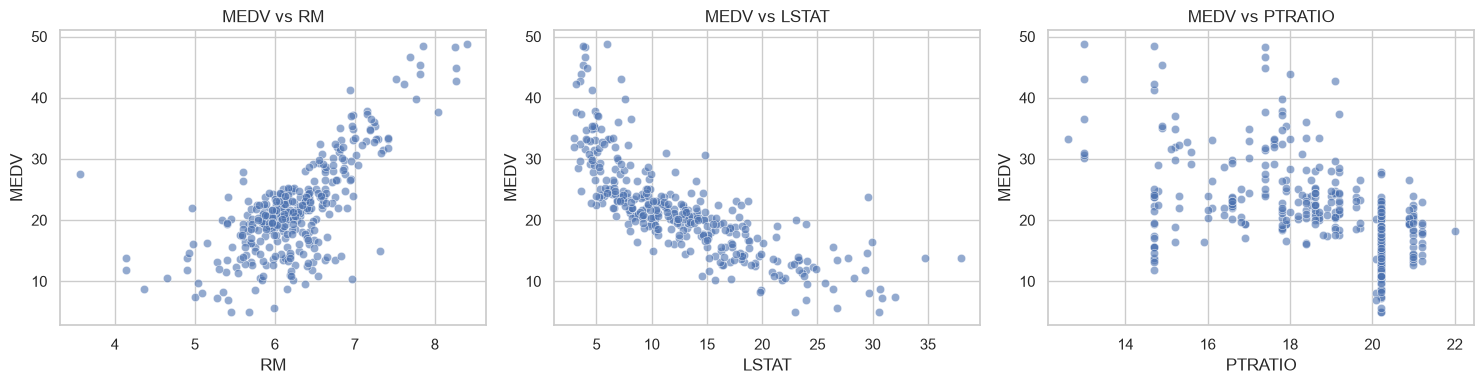

In [20]:
# MEDV contra las más correlacionadas, para ver si la relación da como una recta
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "PTRATIO"]):
    sns.scatterplot(data=train, x=col, y="MEDV", ax=ax, alpha=0.6)
    ax.set_title(f"MEDV vs {col}")
plt.tight_layout()
plt.show()

### Lectura de los gráficos

Los histogramas confirman lo del sesgo: `CRIM` y `ZN` se amontonan cerca de cero con colas
largas, y `CHAS` es casi toda ceros. `MEDV` decrece de corrido, sin amontonarse en ningún
valor puntual.

En los diagramas de caja hay un montón de puntos fuera de los bigotes, sobre todo en `CRIM`.
Decidimos no eliminarlos, y conviene marcar la diferencia con las topeadas que sí
sacamos. Un valor alto de criminalidad es un dato real: ese barrio tiene esa tasa, y es
justo el tipo de barrio que el modelo tiene que poder predecir. Un `MEDV` de 50, en cambio,
es un dato que no conocemos. Sacamos los segundos porque no son información y dejamos los
primeros porque sí lo son. Recortar los atípicos reales nos mejoraría las métricas de
mentira, entrenando y evaluando sobre una versión más fácil del problema.

Los scatterplots muestran las dos relaciones más aprovechables para un modelo lineal: `RM`
sube con `MEDV` (más habitaciones, más valor) y `LSTAT` baja (más población de menor estatus
socioeconómico, menos valor). La de `LSTAT` se ve bastante curva, así que si la dejamos así
vamos a tener error sistemático en los extremos. Lo retomamos con el pairplot.

## Matriz de correlación

Miramos dos cosas: qué características se relacionan más con `MEDV`, y cuáles están muy
correlacionadas entre sí. Lo segundo importa porque cuando dos variables son casi
combinación lineal una de otra, los coeficientes se vuelven inestables: el ajuste puede
repartir el peso entre las dos de muchas formas equivalentes.

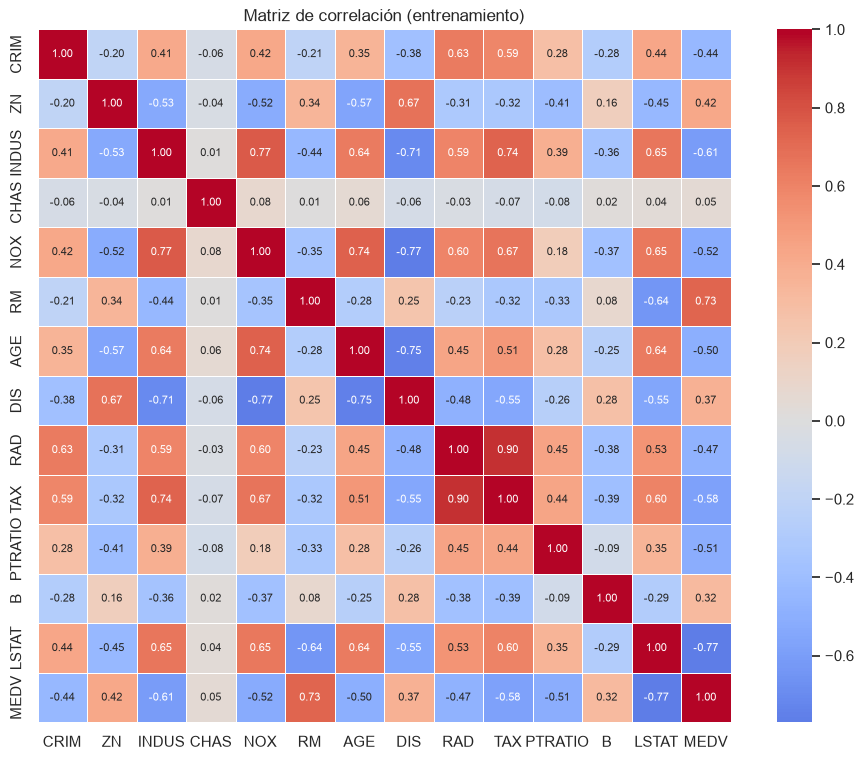

In [21]:
# Matriz de correlación de Pearson sobre el entrenamiento
correlacion = train.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, annot_kws={"size": 8})
plt.title("Matriz de correlación (entrenamiento)")
plt.show()

In [22]:
# Ordenamos la correlación de cada característica con la variable a predecir
correlacion["MEDV"].drop("MEDV").sort_values(key=abs, ascending=False).to_frame("correlación con MEDV").round(3)

,correlación con MEDV
LSTAT,-0.771
RM,0.729
INDUS,-0.610
TAX,-0.579
NOX,-0.525
PTRATIO,-0.509
AGE,-0.498
RAD,-0.475
CRIM,-0.444
ZN,0.425


In [23]:
# Buscamos pares muy correlacionados entre sí, que son los que dejan coeficientes inestables
import itertools

pares = [(a, b, correlacion.loc[a, b]) for a, b in itertools.combinations(X.columns, 2)
         if abs(correlacion.loc[a, b]) > 0.7]
pd.DataFrame(pares, columns=["variable A", "variable B", "correlación"]).round(3)

,variable A,variable B,correlación
0,INDUS,NOX,0.767
1,INDUS,DIS,-0.708
2,INDUS,TAX,0.735
3,NOX,AGE,0.738
4,NOX,DIS,-0.769
5,AGE,DIS,-0.751
6,RAD,TAX,0.904


### Lectura de la correlación

Las dos más fuertes con `MEDV` son `LSTAT` (−0,771) y `RM` (0,729). Después vienen `INDUS`
(−0,610), `TAX` (−0,579), `NOX` (−0,525) y `PTRATIO` (−0,509). Todas con el signo que uno
esperaría: más pobreza, más industria, más contaminación y más chicos por maestro tiran el
precio para abajo, y más habitaciones lo suben.

La excepción es `CHAS`, con 0,048: lindar con el río prácticamente no distingue el valor de
una vivienda. Queda como la variable menos informativa del conjunto. Igual la dejamos,
porque que no sirva sola no quiere decir que no aporte junto a las demás.

Entre las características hay bastante colinealidad. La peor es `RAD`–`TAX` (0,904): los
barrios con más acceso a autopistas son también los de más carga impositiva. El resto de los
pares fuertes son todos del mismo grupo de variables, que describen desde distintos ángulos
qué tan industrial y qué tan céntrico es un barrio: `INDUS` va con `NOX` (0,767) y con `TAX`
(0,735), `NOX` sube cuando baja `DIS` (−0,769) y sube con `AGE` (0,738), y `AGE` baja con
`DIS` (−0,751). Más industria va con más contaminación, y las zonas industriales son las
viejas y cercanas a los centros de empleo.

Dejamos las dos variables de cada par. La colinealidad no impide ajustar el modelo, pero
vuelve inestables los coeficientes, y sacar una a mano sería decidir arbitrariamente cuál de
las dos importa. Ahora bien, la correlación mira de a pares y eso no alcanza para
dimensionar el problema, así que calculamos el VIF.

## Test de colinealidad: el VIF

La matriz de correlación mira las variables de a pares, y eso deja un agujero: una variable
puede no tener ninguna correlación alta con ninguna otra por separado y aun así ser casi una
combinación lineal de varias juntas. Con la correlación no lo veríamos.

El VIF tapa ese agujero. Para cada característica se hace una regresión lineal que la
predice usando **todas las demás**, se saca su $R^2_j$ y se calcula:

$$VIF_j = \frac{1}{1 - R^2_j}$$

Se lee fácil. Si una variable no se puede predecir a partir de las otras, su $R^2_j$ da
cerca de 0 y el VIF cerca de 1. Si se puede predecir casi perfecto, $R^2_j$ tiende a 1 y el
VIF se dispara. El nombre viene de lo que mide: cuántas veces se infla la varianza del
coeficiente estimado por culpa de la colinealidad. Un VIF de 9 quiere decir que el error
estándar de ese coeficiente es $\sqrt{9} = 3$ veces más grande que si la variable fuera
independiente del resto, o sea un coeficiente tres veces más inestable.

Usamos los umbrales que vimos en clase: VIF > 10 es colinealidad severa y VIF > 5 es
moderada.

In [24]:
# El VIF se calcula con regresiones lineales, así que lo importamos acá
from sklearn.linear_model import LinearRegression

In [25]:
def calcular_vif(datos):
    """Regresa cada variable contra todas las demás y devuelve su VIF = 1 / (1 - R²)."""
    filas = []
    for col in datos.columns:
        resto = datos.drop(columns=col)
        r2 = LinearRegression().fit(resto, datos[col]).score(resto, datos[col])
        filas.append({"variable": col, "R²": r2, "VIF": 1 / (1 - r2)})
    return pd.DataFrame(filas).set_index("variable").sort_values("VIF", ascending=False)

In [26]:
# VIF de las 13 características sobre el conjunto de entrenamiento
vif = calcular_vif(X_train)
vif.round(2)

,R²,VIF
variable,,
TAX,0.89,8.86
RAD,0.86,7.09
NOX,0.78,4.62
INDUS,0.76,4.19
DIS,0.75,4.00
LSTAT,0.70,3.36
AGE,0.69,3.18
ZN,0.57,2.32
RM,0.52,2.08


In [27]:
# Vemos cuáles pasan los umbrales que usamos de referencia
print(f"Colinealidad severa (VIF > 10):  {list(vif.index[vif['VIF'] > 10]) or 'ninguna'}")
print(f"Colinealidad moderada (VIF > 5): {list(vif.index[(vif['VIF'] > 5) & (vif['VIF'] <= 10)]) or 'ninguna'}")

Colinealidad severa (VIF > 10):  ninguna
Colinealidad moderada (VIF > 5): ['TAX', 'RAD']


### Lectura del VIF

Ninguna variable llega a colinealidad severa. Las dos más altas son `TAX` (8,86) y `RAD`
(7,09), que quedan en moderada, y el resto está por debajo de 5. Son justo las dos del par
más correlacionado de la matriz (0,90), así que el VIF confirma lo que veíamos pero con más
precisión: esa correlación de 0,90 impresiona, y lo que significa en términos de
inestabilidad es que el error estándar del coeficiente es unas tres veces el normal. Es un
problema, pero no es una catástrofe.

Lo que nos pareció más útil es cómo corrige la lectura por pares. `INDUS` aparecía en tres
de los siete pares fuertes de la matriz (con `NOX`, `TAX` y `DIS`) y podía parecer la más
comprometida de todas; su VIF da 4,19, por debajo del umbral moderado. Que una variable se
correlacione con varias no significa que sea redundante: puede compartir un pedazo con cada
una y seguir teniendo información propia. El VIF, que las mira a todas juntas, es el que
responde esa pregunta.

Dos cosas que nos deja para lo que sigue:

1. Explica los cambios de signo que vamos a ver en los coeficientes. Con VIF de 7 y 9, el
   modelo puede repartir peso entre `RAD` y `TAX` de varias formas casi equivalentes, y cuál
   elige depende de la muestra.
2. Acota lo que podemos esperar de Ridge. Ridge sirve cuando la colinealidad infla la
   varianza de los coeficientes, y acá la infla en serio, así que vale la pena probarlo.
   Pero como ninguna está en zona severa, no esperamos una mejora grande en predicción: lo
   que debería mejorar sobre todo es la estabilidad de los coeficientes. Queda anotado para
   ver si se cumple.

## Relaciones entre pares de variables

La matriz de correlación resume cada relación en un número, y ese número sólo mide
asociación **lineal**. Dos variables pueden tener una relación fuerte pero curva y dar una
correlación mediocre. Como lo que vamos a ajustar es un modelo lineal, necesitamos ver las
formas y no sólo los coeficientes.

Graficamos el pairplot de las 14 variables sobre entrenamiento. Le pasamos `corner=True`
para quedarnos con el triángulo inferior nomás, porque el superior tiene los mismos gráficos
con los ejes dados vuelta. La fila que más nos interesa es la última, `MEDV` contra cada
característica: ahí se ve si la relación que el modelo va a suponer recta lo es en serio.

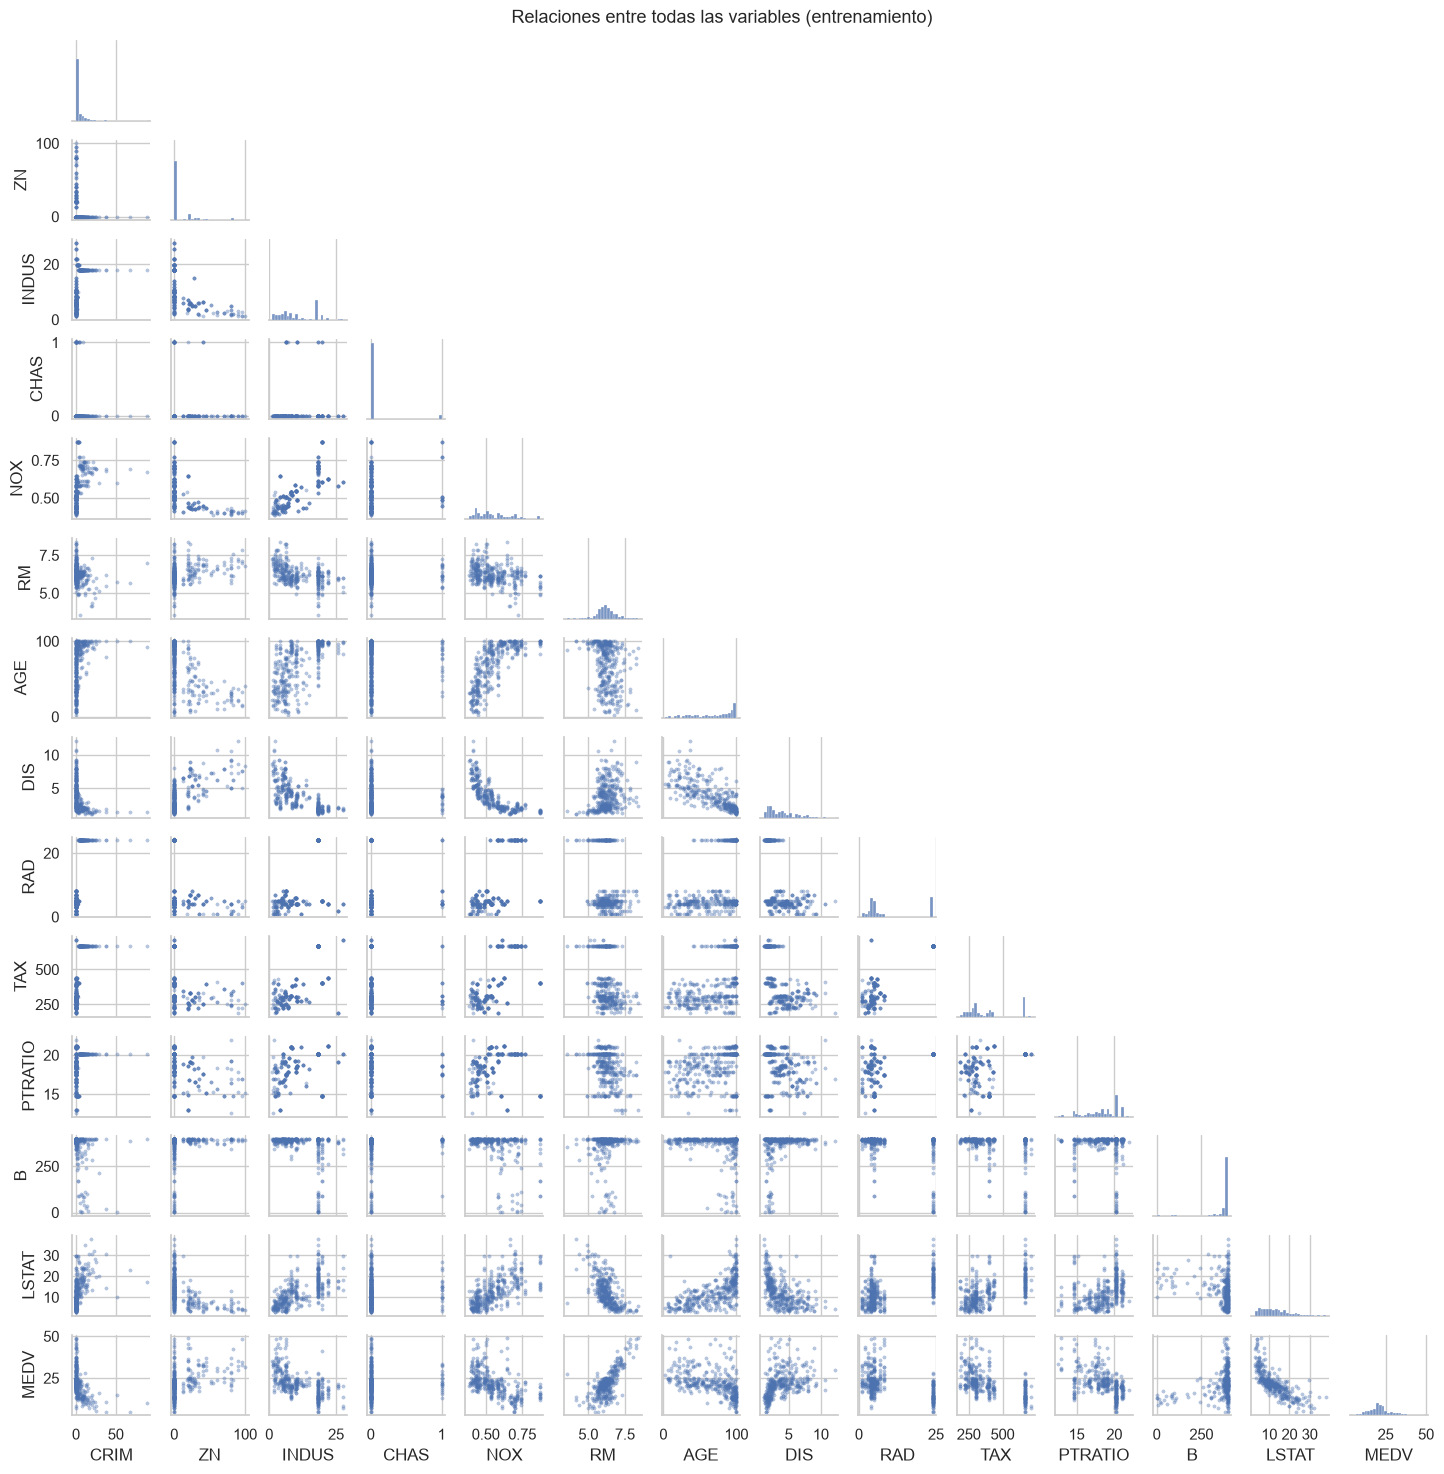

In [28]:
# Pairplot de todo sobre entrenamiento: lo que buscamos son relaciones curvas
g = sns.pairplot(train, corner=True, height=1.05,
                 plot_kws={"s": 6, "alpha": 0.4, "edgecolor": None},
                 diag_kws={"bins": 25})
g.figure.suptitle("Relaciones entre todas las variables (entrenamiento)", y=1.005, fontsize=13)
plt.show()

### Lectura del pairplot

En la última fila, `MEDV` contra cada característica, se ven tres situaciones distintas:

- `LSTAT` tiene una relación claramente curva. Los puntos bajan rápido al principio y
  después se aplanan: es una curva convexa decreciente, no una recta. Pasar de 5% a 10% de
  población de menor estatus socioeconómico hace caer el precio mucho más que pasar de 25% a
  30%. Es el caso típico para aplicar logaritmo, y encima es la variable más correlacionada
  con `MEDV`, así que enderezarla es lo que más nos puede mejorar el ajuste.
- `RM` es la más parecida a una recta, con la nube bien repartida a lo largo de la diagonal.
  No necesita nada.
- `CRIM`, `ZN` y `CHAS` están aplastadas contra un borde. Casi todos los puntos amontonados
  en un extremo y unos pocos estirados lejos. En estas tres el problema no es la curvatura
  sino la escala: la nube ni llega a mostrar una forma.

En las diagonales se confirma lo del sesgo: `CRIM` es la más extrema, `ZN` y `CHAS` se
concentran en cero y las demás son más razonables. También se ven dos variables que se
parten en dos grupos en vez de repartirse continuo, `RAD` y `TAX`: hay un bloque de barrios
con accesibilidad e impuestos muy altos, separado del resto. Es la misma estructura que
produce la correlación de 0,90 entre ellas.

## Transformación logarítmica

El pairplot nos mostró que al menos una relación no es recta, y un modelo lineal no puede
capturar eso. Se puede arreglar de dos formas: complicando el modelo, o enderezando la
variable. Vamos por la segunda, porque nos deja mantener el modelo lineal, que es lo que
pide el trabajo.

El logaritmo comprime la cola larga de una distribución asimétrica: separa los valores
chicos, que estaban amontonados, y junta los grandes, que estaban desparramados. Cuando la
relación con la variable a predecir es del tipo "al principio el efecto es fuerte y después
se agota", eso es justo lo que la convierte en una recta.

Para elegir qué transformar nos pusimos tres condiciones, y tienen que darse las tres:

1. La variable tiene que ser estrictamente positiva (el logaritmo no existe en 0 ni en
   negativos).
2. Tiene que tener sesgo positivo apreciable.
3. El logaritmo tiene que fortalecer su relación lineal con `MEDV`, que es lo único que le
   importa al modelo. Que una variable sea asimétrica no es un problema en sí: las
   distribuciones asimétricas no violan ningún supuesto de la regresión lineal. El problema
   es la relación curva.

La decisión la tomamos mirando sólo entrenamiento. Después aplicar el logaritmo a los tres
conjuntos no es filtración: a diferencia del escalado, transforma cada valor por separado
con una función fija y no estima ningún parámetro a partir de los datos.

In [29]:
# Candidatas: las estrictamente positivas y con sesgo positivo apreciable
candidatas = [c for c in X_train.columns if X_train[c].min() > 0 and X_train[c].skew() > 0.5]
print(f"Candidatas a transformar: {candidatas}")

Candidatas a transformar: ['CRIM', 'NOX', 'DIS', 'RAD', 'TAX', 'LSTAT']


In [30]:
# Para cada una: cuánto le corrige el sesgo el log y cuánto le mejora la relación con MEDV
comparacion = pd.DataFrame({
    "sesgo": X_train[candidatas].skew(),
    "sesgo con log": np.log(X_train[candidatas]).skew(),
    "r con MEDV": [X_train[c].corr(y_train) for c in candidatas],
    "r con log": [np.log(X_train[c]).corr(y_train) for c in candidatas],
}).round(3)
comparacion["mejora |r|"] = (comparacion["r con log"].abs() - comparacion["r con MEDV"].abs()).round(3)
comparacion.sort_values("mejora |r|", ascending=False)

,sesgo,sesgo con log,r con MEDV,r con log,mejora |r|
CRIM,5.394,0.467,-0.444,-0.577,0.133
DIS,0.989,0.112,0.366,0.439,0.073
LSTAT,0.896,-0.236,-0.771,-0.830,0.059
NOX,0.815,0.443,-0.525,-0.534,0.009
TAX,0.731,0.389,-0.579,-0.582,0.003
RAD,1.076,0.264,-0.475,-0.421,-0.054


### Qué transformamos y qué no

La tabla nos separó las candidatas en tres grupos:

- `NOX`, `TAX` y `RAD`: el logaritmo les corrige el sesgo pero la relación con `MEDV` no
  mejora, y en `RAD` incluso empeora (de 0,475 a 0,421). Quedan afuera: corregir el sesgo
  por sí solo no le sirve de nada al modelo.
- `LSTAT`: el sesgo pasa de 0,90 a −0,24 y la correlación con `MEDV` sube de −0,771 a
  −0,830. Es la mejora más grande y coincide con la curvatura que veíamos en el pairplot.
  La transformamos.
- `CRIM` y `DIS`: acá tuvimos que mirar más de cerca, porque los números invitan a
  transformarlas (`CRIM` mejora su correlación de −0,444 a −0,577) y sin embargo terminamos
  no haciéndolo. El motivo está en la celda que sigue.

In [31]:
# ¿Y si también transformamos CRIM? Comparamos el VIF en los dos casos
X_log_lstat = X_train.copy()
X_log_lstat["LSTAT"] = np.log(X_log_lstat["LSTAT"])

X_log_ambas = X_log_lstat.copy()
X_log_ambas["CRIM"] = np.log(X_log_ambas["CRIM"])

pd.DataFrame({"sin log": calcular_vif(X_train)["VIF"],
              "log LSTAT": calcular_vif(X_log_lstat)["VIF"],
              "log LSTAT y CRIM": calcular_vif(X_log_ambas)["VIF"]}
             ).sort_values("log LSTAT y CRIM", ascending=False).round(2)

,sin log,log LSTAT,log LSTAT y CRIM
variable,,,
RAD,7.09,7.08,9.60
TAX,8.86,8.88,8.90
CRIM,1.76,1.74,8.11
NOX,4.62,4.60,4.94
INDUS,4.19,4.20,4.22
LSTAT,3.36,4.10,4.13
DIS,4.00,4.03,3.97
AGE,3.18,3.39,3.44
ZN,2.32,2.34,2.40


Esto nos sacó la duda. Transformar `LSTAT` no le mueve el VIF a nadie: el suyo sube de 3,36
a 4,10, sigue por debajo del umbral, y el resto queda igual. Transformar `CRIM`, en cambio,
le dispara el VIF de 1,76 a 8,11 y de paso empuja a `RAD` de 7,09 a 9,60, al borde de la
colinealidad severa.

El motivo es el mismo que vamos a ver con los coeficientes del modelo. Que `log(CRIM)` se
correlacione mejor con `MEDV` no quiere decir que aporte información nueva: un VIF de 8,11
dice que el 88% de `log(CRIM)` se puede predecir a partir de las otras doce variables. La
señal que gana en la correlación es señal que `RAD`, `TAX` y `NOX` ya estaban aportando. O
sea que lo que sumaría al modelo no es información, es inestabilidad, y no nos parece que
compense justo después de habernos armado un diagnóstico para medirla.

Con `DIS` el caso es distinto: no empeora la colinealidad, pero la mejora en la correlación
es la mitad que la de `LSTAT` y su relación con `MEDV` en el pairplot no se ve curva, así
que no hay curvatura que corregir.

Así que transformamos solamente `LSTAT`.

In [32]:
# Aplicamos el log a las que elegimos, en los tres conjuntos igual
VARIABLES_LOG = ["LSTAT"]

X_train_log, X_val_log, X_test_log = X_train.copy(), X_val.copy(), X_test.copy()
for col in VARIABLES_LOG:
    for conjunto in (X_train_log, X_val_log, X_test_log):
        conjunto[col] = np.log(conjunto[col])

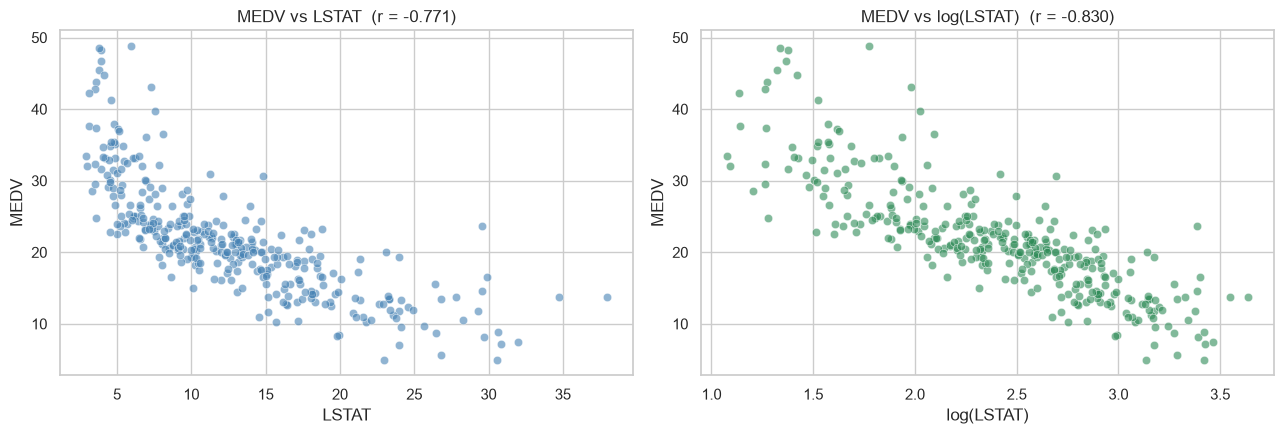

In [33]:
# Chequeamos que haya funcionado: la relación con MEDV tendría que quedar más recta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x=X_train["LSTAT"], y=y_train, ax=axes[0], alpha=0.6, color="steelblue")
axes[0].set_title(f"MEDV vs LSTAT  (r = {X_train['LSTAT'].corr(y_train):.3f})")
sns.scatterplot(x=X_train_log["LSTAT"], y=y_train, ax=axes[1], alpha=0.6, color="seagreen")
axes[1].set_xlabel("log(LSTAT)")
axes[1].set_title(f"MEDV vs log(LSTAT)  (r = {X_train_log['LSTAT'].corr(y_train):.3f})")
plt.tight_layout()
plt.show()

Quedó como esperábamos. En el gráfico de la izquierda los puntos bajan rápido y después se
aplanan, que es la curva que no puede seguir una recta. En el de la derecha la nube ya se
acomoda alrededor de una recta, sin esa panza, y la correlación sube de −0,771 a −0,830.
Con esto la variable más importante del modelo entra en una forma que la regresión lineal
puede aprovechar.

## Codificación de variables categóricas

Acá no hay nada que codificar:

- Las catorce columnas vinieron numéricas y ese tipo es el correcto en todos los casos. No
  hay ninguna columna de texto ni ninguna categoría nominal.
- `CHAS` es la única categórica del conjunto, pero es binaria y ya viene como 0/1, que es
  justo lo que daría aplicarle codificación *dummy*.
- `RAD` es la única que nos hizo dudar, porque toma nueve valores distintos y podría pasar
  por categórica. Pero es un índice **ordinal**: más alto significa más accesibilidad a las
  autopistas. Dejarla como numérica conserva ese orden, que es información útil. Con
  *one-hot* quedarían nueve columnas sin relación entre sí, perdiendo el orden y sumando
  dimensiones sin ganar nada.

## Escalado de los datos

Estandarizamos: a cada variable le restamos su media y la dividimos por su desvío, para que
todas queden en una escala comparable. Es indispensable para el gradiente descendente (con
escalas dispares converge lento y mal) y para la regularización, donde la penalización
compara los coeficientes entre sí y sin escalar castigaría más a unas variables que a otras
sólo por la unidad en la que están medidas. A `CHAS` también la escalamos: al ser binaria el
cambio es cosmético, pero así no tenemos que tratar esa columna aparte.

Escalamos las variables ya transformadas, o sea con `LSTAT` en logaritmo. El orden importa:
estandarizar y después tomar logaritmo no daría lo mismo (habría valores negativos), y
además lo que queremos centrar y reescalar es la variable tal como va a entrar al modelo.

El escalador aprende dos parámetros de los datos, la media y el desvío de cada variable, así
que lo ajustamos sólo con entrenamiento y después lo aplicamos, tal como quedó, a validación
y prueba.

In [34]:
# El escalador, configurado para que devuelva DataFrame y no array
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().set_output(transform="pandas")

In [35]:
# Lo ajustamos con entrenamiento y a los otros dos sólo les aplicamos lo ya ajustado
X_train_prep = escalador.fit_transform(X_train_log)
X_val_prep = escalador.transform(X_val_log)
X_test_prep = escalador.transform(X_test_log)

In [36]:
# Chequeamos el escalado: entrenamiento tiene que dar media 0 y desvío 1, los otros dos no
pd.DataFrame({"media train": X_train_prep.mean(), "desvío train": X_train_prep.std(),
              "media val": X_val_prep.mean(), "desvío val": X_val_prep.std(),
              "media test": X_test_prep.mean(), "desvío test": X_test_prep.std()}).round(3)

,media train,desvío train,media val,desvío val,media test,desvío test
CRIM,0.0,1.001,0.062,1.274,0.026,0.917
ZN,-0.0,1.001,-0.136,0.863,-0.003,1.060
INDUS,-0.0,1.001,0.081,1.010,0.036,1.055
CHAS,-0.0,1.001,-0.064,0.874,0.115,1.203
NOX,0.0,1.001,0.146,0.998,0.087,0.965
RM,-0.0,1.001,0.098,1.070,-0.030,1.062
AGE,-0.0,1.001,0.074,1.005,0.103,0.919
DIS,-0.0,1.001,-0.023,0.871,-0.026,1.099
RAD,-0.0,1.001,0.146,1.063,0.062,1.039
TAX,-0.0,1.001,0.185,1.037,0.042,1.015


Esta última tabla es la confirmación de que no hubo filtración. Entrenamiento queda con
media exactamente 0 y desvío 1, porque es el que se usó para calcular esos parámetros. (La
tabla muestra 1,001 y no 1 por una diferencia de convención: `StandardScaler` divide por el
desvío poblacional y `pandas` informa el muestral.) Validación y prueba no dan 0 y 1: sus
valores se transformaron con la media y el desvío de entrenamiento, sin que sus propios
datos entraran en el cálculo. Si esta tabla diera 0 y 1 exactos en las tres columnas, sería
señal de que escalamos todo junto y de que las métricas están contaminadas.

Cuánto se apartan de 0 y 1 depende de la variable, y en algunas la diferencia es grande. Son
las más asimétricas y la binaria, que dependen de unos pocos valores extremos o de una
proporción baja de unos. En un conjunto de 49 filas, que caigan unos pocos casos atípicos de
más o de menos mueve mucho el desvío. No es un problema del escalado, es un recordatorio de
que validación es chica y de que sus métricas hay que leerlas con margen: sirven para
ordenar configuraciones, no para estimar con precisión el error del modelo.

Con esto terminamos el preprocesamiento. Arrancamos con 556 filas y llegamos a 490
utilizables: sacamos 50 incompletas y 16 con el precio topeado en 50. Las 13 características
quedaron con `LSTAT` en logaritmo y todas estandarizadas, repartidas en 343 filas de
entrenamiento, 49 de validación y 98 de prueba (70% / 10% / 20%). Listos para entrenar.

# Regresión lineal múltiple

Con los datos listos pasamos a modelar. La regresión lineal múltiple supone que `MEDV` se
puede escribir como una combinación lineal de las 13 características:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_{13} x_{13}$$

donde $w_0$ es la ordenada al origen y cada $w_j$ es el peso de una característica. Entre
los métodos de este ítem lo que cambia no es la forma del modelo sino cómo se buscan esos
pesos: mínimos cuadrados los resuelve de una con una fórmula, el gradiente descendente los
va corrigiendo de a poco, y la regularización le agrega a esa búsqueda una penalización al
tamaño de los pesos. Arrancamos por el primero.

## Las métricas que vamos a usar

El enunciado pide elegir entre R², MSE, RMSE, MAE y MAPE. Nos quedamos con tres, porque cada
una contesta algo distinto y juntas se complementan:

- **R²**: qué proporción de la variabilidad de `MEDV` explica el modelo. No tiene unidades,
  así que sirve para comparar entre conjuntos de distinto tamaño y contra un modelo trivial:
  R² = 0 es predecir siempre el promedio y R² = 1 es acertar exacto. Es la que usamos de
  referencia para comparar modelos.
- **RMSE**: queda en las mismas unidades que `MEDV` (miles de dólares), así que se lee
  directo como "el modelo se equivoca en promedio en tantos miles". Además es la raíz de la
  función que mínimos cuadrados y el gradiente descendente minimizan, o sea que mide justo
  lo que el modelo está tratando de optimizar. Como eleva los errores al cuadrado, castiga
  fuerte los desvíos grandes.
- **MAE**: también en miles de dólares, pero promedia los errores sin elevarlos al cuadrado,
  así que no se le infla por unos pocos casos muy errados. Mirarlo junto al RMSE es
  informativo: si el RMSE es bastante más grande que el MAE, quiere decir que el error no
  está repartido parejo sino concentrado en unas pocas observaciones mal predichas.

Las otras dos las descartamos. El MSE tiene la misma información que el RMSE pero en "miles
de dólares al cuadrado", una unidad que no se puede interpretar; el RMSE es el mismo número
ya devuelto a una escala legible. El MAPE mide el error como porcentaje del valor real, y
acá eso distorsiona: `MEDV` va de 5 a 50, así que errar por 2 en una vivienda de 5 pesaría
diez veces más que el mismo error en una de 50, cuando para el problema los dos errores
valen igual.

### Por qué medimos sobre entrenamiento y sobre prueba

Es una de las preguntas del enunciado. Mirar uno solo de los dos no alcanza:

- Sólo entrenamiento mide qué tan bien el modelo reproduce los datos que ya vio, y eso no
  dice nada sobre datos nuevos: un modelo con suficiente flexibilidad puede memorizar el
  entrenamiento y después fallar por completo afuera.
- Sólo prueba dice si el modelo sirve, pero no por qué cuando no sirve, y el diagnóstico
  cambia por completo qué habría que hacer.

Lo que informa es la diferencia entre las dos. Si el modelo anda bien en entrenamiento y mal
en prueba, está sobreajustado: aprendió el ruido de esas filas y hay que simplificarlo o
regularizarlo. Si anda mal en los dos, está subajustado: es demasiado rígido para la
relación que hay en los datos, y regularizar lo empeoraría todavía más. Sin la métrica de
entrenamiento no podemos distinguir un caso del otro.

In [37]:
# El modelo de mínimos cuadrados y las tres métricas que elegimos
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [38]:
def metricas(y_real, y_pred):
    """Devuelve las tres métricas elegidas para un conjunto dado."""
    return pd.Series({"R²": r2_score(y_real, y_pred),
                      "RMSE": root_mean_squared_error(y_real, y_pred),
                      "MAE": mean_absolute_error(y_real, y_pred)})

In [39]:
def evaluar(pred_train, pred_val, pred_test):
    """Arma la tabla de métricas de un modelo sobre los tres conjuntos."""
    return pd.DataFrame({"entrenamiento": metricas(y_train, pred_train),
                         "validación": metricas(y_val, pred_val),
                         "prueba": metricas(y_test, pred_test)}).round(3)

In [40]:
def tabla_comparativa(predicciones):
    """Igual que evaluar pero para varios modelos: recibe {modelo: {conjunto: predicción}}."""
    reales = {"entrenamiento": y_train, "validación": y_val, "prueba": y_test}
    filas = {(modelo, conjunto): metricas(reales[conjunto], pred)
             for modelo, preds in predicciones.items()
             for conjunto, pred in preds.items()}
    return pd.DataFrame(filas).T.round(4)

In [41]:
# Acá vamos guardando las métricas de prueba de cada modelo, para compararlos al final
resultados = {}

## `LinearRegression`: mínimos cuadrados

`LinearRegression` busca los pesos que minimizan la suma de los errores al cuadrado sobre
entrenamiento. No los busca probando: ese problema tiene solución exacta, que sale de
resolver un sistema de ecuaciones, así que el modelo llega al óptimo de una, sin iteraciones
y sin hiperparámetros que elegir. Por eso lo usamos de punto de partida: da el mejor ajuste
lineal posible sobre entrenamiento, y todo lo demás se compara contra él.

Lo entrenamos con los datos escalados. A mínimos cuadrados el escalado no le hace falta (la
solución exacta no depende de la escala), pero lo usamos igual por dos motivos: los
coeficientes quedan todos en la misma unidad y se pueden comparar entre sí, y todos los
modelos del trabajo quedan entrenados exactamente sobre los mismos datos, que es condición
para que la comparación del ítem 6 sea justa.

In [42]:
# Entrenamos el modelo con los datos escalados
lineal = LinearRegression()
lineal.fit(X_train_prep, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-1.27, 0.4 ,-0.15,...,-1.52, 0.83,-3.71]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,21.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [43]:
# Chequeamos que a mínimos cuadrados el escalado no le cambia las predicciones
sin_escalar = LinearRegression().fit(X_train_log, y_train)
print(f"R² de prueba con datos escalados:   {r2_score(y_test, lineal.predict(X_test_prep)):.6f}")
print(f"R² de prueba sin escalar:           {r2_score(y_test, sin_escalar.predict(X_test_log)):.6f}")

R² de prueba con datos escalados:   0.769052
R² de prueba sin escalar:           0.769052


In [44]:
# La ordenada al origen, comparada con el precio promedio
print(f"Ordenada al origen (w0): {lineal.intercept_:.3f}")
print(f"Precio medio en entrenamiento: {y_train.mean():.3f}")

Ordenada al origen (w0): 21.802
Precio medio en entrenamiento: 21.802


In [45]:
# Los coeficientes ordenados por tamaño, para ver cuánto pesa cada variable
coeficientes = pd.Series(lineal.coef_, index=X_train_prep.columns)
coeficientes.sort_values(key=abs, ascending=False).to_frame("coeficiente").round(3)

,coeficiente
LSTAT,-3.715
DIS,-2.321
RM,2.147
RAD,2.104
TAX,-1.980
PTRATIO,-1.523
CRIM,-1.265
NOX,-0.980
B,0.826
ZN,0.398


### Lectura de los coeficientes

La ordenada al origen da 21,80, que es justo el precio medio del entrenamiento. Tiene
sentido: como las características están centradas en 0, un barrio que sea promedio en las
trece tiene todos los términos $w_j x_j$ en cero, así que el modelo le predice $w_0$. Con
datos estandarizados el intercepto es la predicción para el barrio promedio.

Como todas las variables están en desvíos estándar, los coeficientes se leen igual entre sí:
cuánto cambia el precio predicho, en miles de dólares, si esa variable sube un desvío y las
demás quedan fijas. `LSTAT` es la más influyente por lejos (−3,72), ahora en su versión
logarítmica. Después vienen `DIS` (−2,32), `RM` (2,15), `RAD` (2,10) y `TAX` (−1,98).

Hay algo que no cierra con la matriz de correlación y conviene frenar acá. Por sí sola,
`DIS` se correlaciona positivamente con `MEDV` (0,366), pero su coeficiente en el modelo da
negativo. Con `RAD` pasa al revés: correlación −0,475 y coeficiente +2,10. Las dos cambian
de signo al pasar de la correlación al modelo.

No es un error, es justo lo que nos había anticipado el VIF. La correlación mira la variable
sola, mientras que el coeficiente mide lo que aporta dado que las demás ya están en el
modelo. `DIS` venía muy correlacionada con `NOX` (−0,769) y con `AGE` (−0,751); una vez que
esas dos explican la parte de "barrio viejo y contaminado", lo que `DIS` agrega por encima
cambia de signo. Lo mismo con `RAD`–`TAX` (0,904), el par más colineal y el de los VIF más
altos (7,09 y 8,86): con `TAX` adentro, el aporte propio de `RAD` se da vuelta.

Lo importante de esto es que estos coeficientes no son confiables uno por uno. Un VIF de
8,86 en `TAX` significa que el error estándar de su coeficiente es casi tres veces el que
tendría sin colinealidad, así que otra muestra repartiría el peso entre `RAD` y `TAX` de
otra forma. Sirven para predecir, no para salir a afirmar que tener autopistas cerca
encarece las viviendas. Es el escenario donde Ridge debería ayudar, y lo vemos más
adelante.

In [46]:
# Predecimos en los tres conjuntos
pred_train = lineal.predict(X_train_prep)
pred_val = lineal.predict(X_val_prep)
pred_test = lineal.predict(X_test_prep)

In [47]:
# Métricas en los tres conjuntos, y las guardamos para la comparación del final
tabla_lineal = evaluar(pred_train, pred_val, pred_test)
resultados["LinearRegression"] = tabla_lineal["prueba"]
tabla_lineal

,entrenamiento,validación,prueba
R²,0.831,0.663,0.769
RMSE,3.225,4.322,3.878
MAE,2.453,3.025,2.850


### Lectura de las métricas

El modelo explica el 77% de la variabilidad del precio en prueba (R² = 0,769) y se equivoca
en promedio unos 3.900 dólares (RMSE = 3,878), sobre un precio mediano de 20.900. O sea, un
error del orden del 19% del valor típico de una vivienda. No es un modelo preciso, pero
captura buena parte de la señal.

Comparando entre conjuntos, no hay sobreajuste serio. El R² baja de 0,831 en entrenamiento a
0,769 en prueba: hay una caída pero es moderada y era esperable. Con 13 características y
343 filas, un modelo lineal no tiene flexibilidad como para memorizar el entrenamiento
aunque quisiera. Si este modelo tiene algún problema, va para el otro lado.

El R² de validación (0,663) queda bastante por debajo del de prueba, lo que a primera vista
descoloca. No hay que leer mucho en eso: validación tiene 49 filas, y con tan pocas
observaciones la métrica se mueve varios puntos según qué barrios hayan caído ahí. Nos sirve
para ordenar configuraciones, que es para lo que la vamos a usar, no para estimar el error
final.

Lo más informativo es la relación entre RMSE (3,878) y MAE (2,850). Si los errores
estuvieran repartidos parejo los dos números serían parecidos; que el RMSE sea un 36% más
grande dice que el error está concentrado en unas pocas observaciones bastante mal
predichas. Los gráficos que siguen muestran cuáles son.

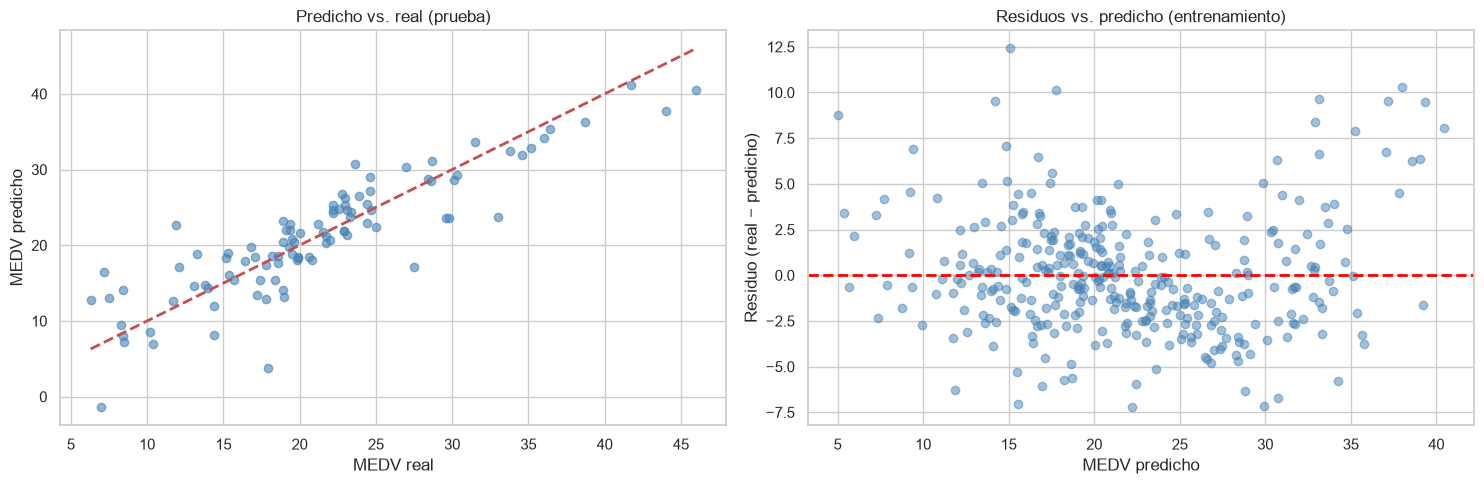

In [48]:
# Dos gráficos para ver cómo ajusta: qué tan cerca cae y cómo se reparte el error
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Predicho contra real en prueba: la diagonal es el ajuste perfecto
axes[0].scatter(y_test, pred_test, alpha=0.6, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("MEDV real")
axes[0].set_ylabel("MEDV predicho")
axes[0].set_title("Predicho vs. real (prueba)")

# Residuos contra predicho en entrenamiento: buscamos que no quede ningún patrón
residuos = y_train - pred_train
axes[1].scatter(pred_train, residuos, alpha=0.5, color="steelblue")
axes[1].axhline(0, color="red", ls="--", lw=2)
axes[1].set_xlabel("MEDV predicho")
axes[1].set_ylabel("Residuo (real − predicho)")
axes[1].set_title("Residuos vs. predicho (entrenamiento)")

plt.tight_layout()
plt.show()

In [49]:
# Residuo medio por tramo: si el modelo estuviera bien, tendría que dar cerca de 0 en todos
tramos = pd.cut(pred_train, [-10, 15, 20, 25, 30, 60])
pd.DataFrame({"residuo medio": residuos.groupby(tramos, observed=True).mean(),
              "viviendas": residuos.groupby(tramos, observed=True).size()}).round(2)

,residuo medio,viviendas
"(-10, 15]",0.66,56
"(15, 20]",0.31,94
"(20, 25]",-0.52,86
"(25, 30]",-1.97,53
"(30, 60]",1.52,54


In [50]:
# Nada le impide a una recta predecir precios negativos, así que lo chequeamos
print(f"Predicción mínima en entrenamiento: {pred_train.min():.2f}")
print(f"Predicción mínima en prueba:        {pred_test.min():.2f}")

Predicción mínima en entrenamiento: 5.03
Predicción mínima en prueba:        -1.41


### ¿Conseguimos un buen fitting?

Nos parece que sí, un ajuste razonable para un modelo lineal, pero con un techo que ya no se
puede correr sin salirse de la regresión lineal. Los gráficos muestran dos problemas, y
ninguno se arregla cambiando el método de optimización.

**La relación no es del todo lineal.** En el gráfico de residuos la nube debería verse como
una banda sin forma alrededor del cero. En cambio los residuos medios por tramo dibujan una
U: son positivos en las viviendas baratas (+0,66 y +0,31), negativos en la franja de 20 a 30
(−0,52 y −1,97) y vuelven a ser positivos en las caras (+1,52). Que el signo del error
dependa del valor predicho significa que al modelo le falta curvatura: subestima en los
extremos y sobreestima en el medio. Enderezar `LSTAT` resolvió la curvatura más marcada,
pero evidentemente no era la única variable con una relación que no es del todo recta.
Corregir lo que queda pediría términos polinómicos o interacciones, que se van del alcance
del ítem.

**Hay una predicción negativa en prueba** (−1,41). Una recta no tiene forma de saber que un
precio no puede bajar de cero, y extrapola sin límite en los barrios más desfavorecidos. Es
una limitación estructural de la regresión lineal sobre una variable acotada por abajo, no
algo que se arregle con más datos.

Contestando la pregunta del enunciado: el problema de este modelo no es sobreajuste (la
caída de 0,831 a 0,769 es moderada) sino sesgo. Es un modelo rígido para la forma que tienen
estos datos.

Eso nos deja dos expectativas escritas, para contrastarlas con lo que viene. El gradiente
descendente busca los mismos pesos por otro camino, así que en el mejor de los casos
debería llegar a métricas equivalentes, nunca mejores; si da algo distinto es que no terminó
de converger. Y la regularización sirve para bajar varianza, que no es nuestro problema, así
que tampoco esperamos una mejora grande en predicción: lo interesante va a ser ver qué le
hace a los coeficientes inestables que nos marcó el VIF en `RAD` y `TAX`.

## Gradiente descendente

Mínimos cuadrados resuelve el problema de una, con una fórmula. El gradiente descendente
llega al mismo lugar pero iterando: arranca con pesos cualquiera y los va corrigiendo de a
poco, siempre en la dirección que más baja el error.

La función de costo que queremos minimizar es el MSE:

$$J(W) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

y su gradiente respecto de los pesos es:

$$\nabla J(W) = -\frac{2}{n} X^T (y - XW)$$

El gradiente apunta hacia donde el error *crece*, así que para bajarlo hay que ir para el
otro lado. De ahí sale la regla de actualización:

$$W \leftarrow W - lr \cdot \nabla J(W)$$

donde $lr$ es el paso de aprendizaje, que decide cuánto nos movemos en cada corrección.

Si ya tenemos la solución exacta, ¿para qué queremos esto? Acá, con 13 variables y 343
filas, la verdad es que no hace falta. Pero el método sirve cuando el dataset es tan grande
que resolver el sistema de ecuaciones no entra en memoria, y sobre todo es la base de cómo
se entrena casi cualquier modelo más complejo, donde solución cerrada directamente no hay.

Implementamos las tres variantes que vimos en clase. Se diferencian en cuántos datos usan
para calcular cada corrección:

- **Por lotes (batch)**: usa las 343 filas en cada paso. El gradiente es el exacto, pero
  cada paso cuesta.
- **Estocástico (SGD)**: usa una sola fila por paso. Cada corrección sale rapidísimo pero
  apunta para cualquier lado.
- **Mini-batch**: el punto medio, va de a grupos de 32 filas.

Acá el escalado que hicimos antes se vuelve imprescindible. Si las variables tuvieran
escalas muy distintas, un mismo `lr` sería enorme para unas y mínimo para otras, y en vez
de bajar derecho el descenso zigzaguearía.

In [51]:
# Las funciones trabajan con arrays de numpy, así que convertimos y dejamos y como columna
X_train_np = X_train_prep.values
X_val_np = X_val_prep.values
X_test_np = X_test_prep.values

y_train_np = y_train.values.reshape(-1, 1)
y_val_np = y_val.values.reshape(-1, 1)

In [52]:
def agregar_unos(X):
    """Le pega una columna de unos a X para que el intercepto entre como un peso más."""
    return np.hstack((np.ones((X.shape[0], 1)), X))

In [53]:
def gradiente_descendente(X_train, y_train, X_val, y_val, lr=0.01, epochs=100):
    """Gradiente descendente por lotes. Devuelve los pesos y el MSE de cada época."""
    n, m = X_train.shape
    X_train, X_val = agregar_unos(X_train), agregar_unos(X_val)

    # Pesos iniciales al azar (fijamos la semilla para poder repetir el resultado)
    np.random.seed(SEMILLA)
    W = np.random.randn(m + 1).reshape(m + 1, 1)

    err_train, err_val = [], []
    for _ in range(epochs):
        error = y_train - X_train @ W
        err_train.append(np.mean(error ** 2))
        err_val.append(np.mean((y_val - X_val @ W) ** 2))

        gradiente = -2 / n * (X_train.T @ error)
        W = W - lr * gradiente

    return W, err_train, err_val

In [54]:
def gradiente_estocastico(X_train, y_train, X_val, y_val, lr=0.001, epochs=100):
    """Igual que el anterior pero actualiza los pesos fila por fila."""
    n, m = X_train.shape
    X_train, X_val = agregar_unos(X_train), agregar_unos(X_val)

    np.random.seed(SEMILLA)
    W = np.random.randn(m + 1).reshape(m + 1, 1)

    err_train, err_val = [], []
    for _ in range(epochs):
        # Guardamos el error una vez por época, para que las curvas se puedan comparar
        err_train.append(np.mean((y_train - X_train @ W) ** 2))
        err_val.append(np.mean((y_val - X_val @ W) ** 2))

        # Barajamos el orden en cada época para no recorrer siempre igual
        for j in np.random.permutation(n):
            x_j = X_train[j:j + 1]
            error_j = y_train[j, 0] - (x_j @ W)[0, 0]
            W = W - lr * (-2 * error_j * x_j.T)

    return W, err_train, err_val

In [55]:
def gradiente_mini_batch(X_train, y_train, X_val, y_val, lr=0.01, epochs=100, batch_size=32):
    """Punto medio: actualiza los pesos de a grupos de batch_size filas."""
    n, m = X_train.shape
    X_train, X_val = agregar_unos(X_train), agregar_unos(X_val)

    np.random.seed(SEMILLA)
    W = np.random.randn(m + 1).reshape(m + 1, 1)

    err_train, err_val = [], []
    for _ in range(epochs):
        err_train.append(np.mean((y_train - X_train @ W) ** 2))
        err_val.append(np.mean((y_val - X_val @ W) ** 2))

        orden = np.random.permutation(n)
        X_mezclado, y_mezclado = X_train[orden], y_train[orden]
        for j in range(0, n, batch_size):
            x_lote = X_mezclado[j:j + batch_size]
            y_lote = y_mezclado[j:j + batch_size]
            error_lote = y_lote - x_lote @ W
            W = W - lr * (-2 / len(x_lote) * (x_lote.T @ error_lote))

    return W, err_train, err_val

In [56]:
def predecir(X, W):
    """Predice con los pesos que devuelven las funciones de gradiente."""
    return (agregar_unos(X) @ W).ravel()

In [57]:
def graficar_error(err_train, err_val, titulo, referencia=None):
    """Curva de error vs épocas. Usamos escala log porque el error arranca altísimo."""
    plt.figure(figsize=(11, 4.5))
    plt.plot(err_train, label="entrenamiento")
    plt.plot(err_val, label="validación")
    if referencia is not None:
        plt.axhline(referencia, color="red", ls="--", lw=1.5, label="MSE de mínimos cuadrados")
    plt.yscale("log")
    plt.xlabel("Época")
    plt.ylabel("MSE (escala logarítmica)")
    plt.title(titulo)
    plt.legend()
    plt.show()

In [58]:
# El MSE que consiguió mínimos cuadrados: es el piso al que debería llegar el gradiente
mse_ols = np.mean((y_train - lineal.predict(X_train_prep)) ** 2)
print(f"MSE de entrenamiento de LinearRegression: {mse_ols:.4f}")

MSE de entrenamiento de LinearRegression: 10.4011


### Gradiente por lotes

Empezamos con `lr = 0.05` y 1000 épocas. Más adelante, en el ítem 5, probamos qué pasa al
cambiar esos valores; por ahora usamos una combinación que converge para poder comparar
contra mínimos cuadrados.

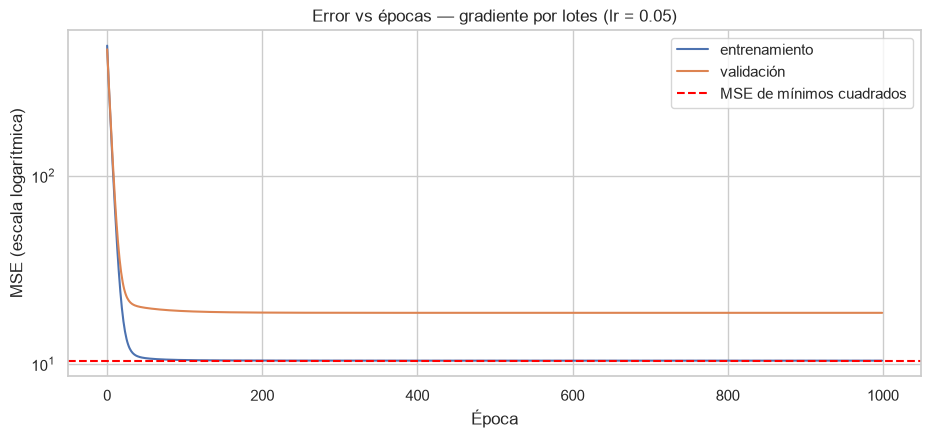

In [59]:
# Entrenamos con el gradiente por lotes y vemos cómo baja el error
W_gd, err_train_gd, err_val_gd = gradiente_descendente(
    X_train_np, y_train_np, X_val_np, y_val_np, lr=0.05, epochs=1000
)
graficar_error(err_train_gd, err_val_gd, "Error vs épocas — gradiente por lotes (lr = 0.05)", mse_ols)

In [60]:
# Comparamos los pesos que encontró con los de mínimos cuadrados
pesos = pd.DataFrame({"mínimos cuadrados": np.concatenate([[lineal.intercept_], lineal.coef_]),
                      "gradiente por lotes": W_gd.ravel()},
                     index=["intercepto"] + list(X_train_prep.columns))
pesos["diferencia"] = pesos["gradiente por lotes"] - pesos["mínimos cuadrados"]
pesos.round(4)

,mínimos cuadrados,gradiente por lotes,diferencia
intercepto,21.8017,21.8017,-0.0000
CRIM,-1.2650,-1.2649,0.0001
ZN,0.3984,0.3982,-0.0002
INDUS,-0.1542,-0.1548,-0.0006
CHAS,0.2246,0.2247,0.0001
NOX,-0.9802,-0.9801,0.0002
RM,2.1473,2.1474,0.0001
AGE,-0.3761,-0.3762,-0.0001
DIS,-2.3214,-2.3214,0.0000
RAD,2.1036,2.1022,-0.0015


In [61]:
# La diferencia más grande entre los dos vectores de pesos
print(f"Diferencia máxima en valor absoluto: {pesos['diferencia'].abs().max():.6f}")
print(f"MSE de entrenamiento: gradiente {err_train_gd[-1]:.4f}  vs  mínimos cuadrados {mse_ols:.4f}")

Diferencia máxima en valor absoluto: 0.001703
MSE de entrenamiento: gradiente 10.4011  vs  mínimos cuadrados 10.4011


La curva baja muy rápido las primeras épocas y después se aplana justo sobre la línea
roja, que es el MSE de mínimos cuadrados. Eso es exactamente lo que esperábamos: el
gradiente no está buscando otra cosa, está buscando el mismo mínimo por otro camino. Arranca
en un MSE de 491 (los pesos iniciales son al azar, así que predice cualquier cosa) y termina
en 10,4011, que es el mismo número que da la fórmula cerrada.

Los pesos también coinciden: la diferencia más grande entre los dos vectores es de 0,0017,
en `TAX`. No es cero porque el gradiente se acerca al mínimo sin llegar nunca del todo, pero
a esta altura la diferencia ya no cambia ninguna predicción.

Las dos curvas, entrenamiento y validación, bajan juntas y ninguna se despega hacia arriba.
Si el modelo estuviera sobreajustando veríamos la de validación empezar a subir en algún
momento mientras la de entrenamiento sigue bajando, y no pasa. Es coherente con lo que
habíamos visto con las métricas.

### Estocástico y mini-batch

Ahora las otras dos variantes. Para SGD hay que usar un `lr` bastante más chico (0,001
contra 0,05): como actualiza los pesos una vez por fila, en una sola época hace 343
correcciones en vez de una, y con un paso grande se pasa de largo.

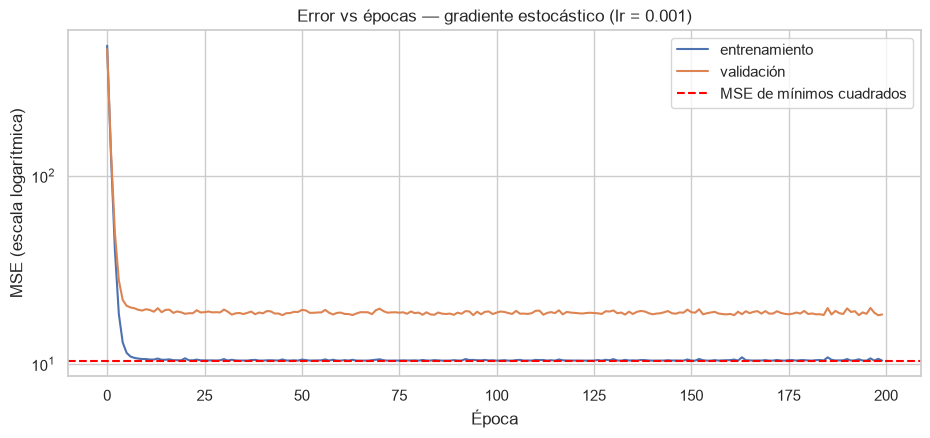

In [62]:
# Gradiente estocástico: una actualización por fila
W_sgd, err_train_sgd, err_val_sgd = gradiente_estocastico(
    X_train_np, y_train_np, X_val_np, y_val_np, lr=0.001, epochs=200
)
graficar_error(err_train_sgd, err_val_sgd, "Error vs épocas — gradiente estocástico (lr = 0.001)", mse_ols)

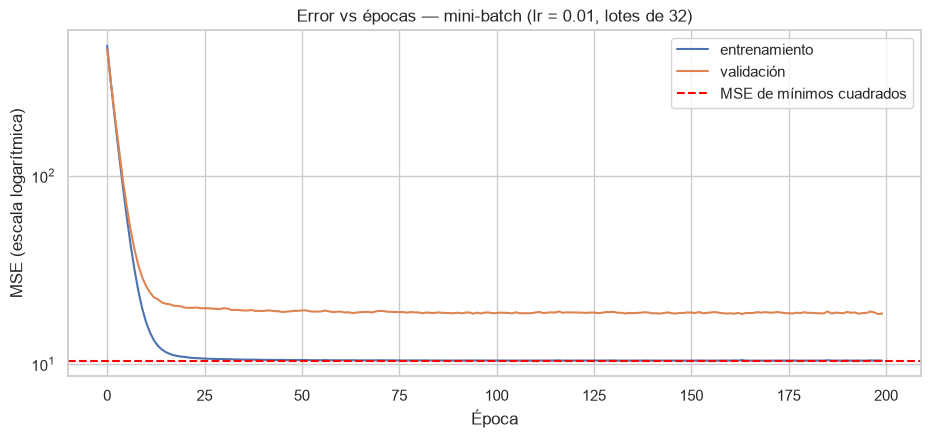

In [63]:
# Mini-batch: una actualización cada 32 filas
W_mb, err_train_mb, err_val_mb = gradiente_mini_batch(
    X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, batch_size=32
)
graficar_error(err_train_mb, err_val_mb, "Error vs épocas — mini-batch (lr = 0.01, lotes de 32)", mse_ols)

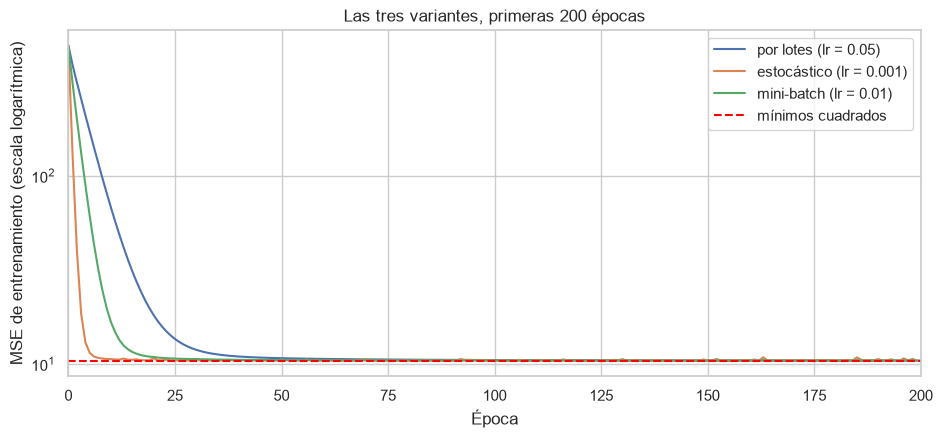

In [64]:
# Las tres curvas juntas, para comparar cuál baja más rápido
plt.figure(figsize=(11, 4.5))
plt.plot(err_train_gd, label="por lotes (lr = 0.05)")
plt.plot(err_train_sgd, label="estocástico (lr = 0.001)")
plt.plot(err_train_mb, label="mini-batch (lr = 0.01)")
plt.axhline(mse_ols, color="red", ls="--", lw=1.5, label="mínimos cuadrados")
plt.yscale("log")
plt.xlim(0, 200)
plt.xlabel("Época")
plt.ylabel("MSE de entrenamiento (escala logarítmica)")
plt.title("Las tres variantes, primeras 200 épocas")
plt.legend()
plt.show()

In [65]:
# Las tres variantes contra mínimos cuadrados, en los tres conjuntos
def preds_gd(W):
    return {"entrenamiento": predecir(X_train_np, W),
            "validación": predecir(X_val_np, W),
            "prueba": predecir(X_test_np, W)}

comparacion_gd = tabla_comparativa({
    "LinearRegression": {"entrenamiento": pred_train, "validación": pred_val, "prueba": pred_test},
    "GD por lotes": preds_gd(W_gd),
    "GD estocástico": preds_gd(W_sgd),
    "GD mini-batch": preds_gd(W_mb),
})
comparacion_gd

R²    RMSE     MAE
LinearRegression entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7691  3.8779  2.8497
GD por lotes     entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7690  3.8779  2.8497
GD estocástico   entrenamiento  0.8270  3.2645  2.4838
                 validación     0.6527  4.3855  3.0346
                 prueba         0.7645  3.9163  2.8496
GD mini-batch    entrenamiento  0.8306  3.2296  2.4552
                 validación     0.6602  4.3378  3.0301
                 prueba         0.7679  3.8872  2.8498

In [66]:
# Guardamos las tres para la comparación final del ítem 6
resultados["GD por lotes"] = metricas(y_test, predecir(X_test_np, W_gd))
resultados["GD estocástico"] = metricas(y_test, predecir(X_test_np, W_sgd))
resultados["GD mini-batch"] = metricas(y_test, predecir(X_test_np, W_mb))
pd.DataFrame(resultados).round(4)

,LinearRegression,GD por lotes,GD estocástico,GD mini-batch
R²,0.769,0.7690,0.7645,0.7679
RMSE,3.878,3.8779,3.9163,3.8872
MAE,2.850,2.8497,2.8496,2.8498


### ¿Algún cambio?

La respuesta corta es **no**, y era lo que teníamos que encontrar.

El gradiente por lotes da un R² de prueba de 0,7690 contra 0,7691 de `LinearRegression`, y
el mismo RMSE hasta el cuarto decimal. Mini-batch queda en 0,7679 y SGD en 0,7645, apenas
por debajo. Las cuatro filas de la tabla son en la práctica el mismo modelo.

Y no puede ser de otra manera. Los cuatro métodos minimizan la misma función de costo sobre
los mismos datos, y esa función tiene un solo mínimo, así que todos apuntan al mismo lugar.
La fórmula cerrada va directo, el gradiente se acerca iterando. Si el gradiente nos hubiera
dado un error *menor* que mínimos cuadrados, tendríamos que sospechar de un error en el
código, porque significaría que la fórmula exacta no encontró el óptimo.

Lo que sí cambia entre las variantes es **cómo** llegan, y ahí está lo interesante:

- **Por lotes** llega al mínimo y se queda quieto. Usa las 343 filas para calcular cada
  gradiente, así que la dirección es la correcta y la curva baja suave, sin sobresaltos.
- **SGD** es el que queda más lejos (sus pesos difieren de los de mínimos cuadrados en 0,22
  contra 0,002 del de lotes). El motivo es que cada paso lo da mirando **una sola vivienda**:
  esa dirección es una estimación muy ruidosa del gradiente verdadero, así que en vez de
  frenar en el mínimo, se la pasa rebotando alrededor. Se nota en la curva, que después de
  bajar queda temblando en vez de aplanarse.
- **Mini-batch** queda en el medio, que es justamente su razón de ser: promediar 32 filas
  cancela buena parte del ruido de SGD sin pagar el costo de recorrer las 343 en cada paso.

En un dataset de 343 filas esa diferencia de costo no se siente y el gradiente por lotes
gana sin discusión. La ventaja de SGD y mini-batch aparece cuando las filas son millones y
recorrerlas todas para dar un solo paso deja de ser viable.

Un detalle que conviene tener presente para el ítem 5: acá elegimos `lr` y épocas para que
el método convergiera. Esa elección **no es gratis** y es la diferencia grande contra
mínimos cuadrados, que no tiene nada que elegir. Con un `lr` demasiado chico el método no
llega en las épocas que le damos, y con uno demasiado grande directamente se escapa. Eso lo
mostramos en el próximo ítem.

## Regularización: Ridge, Lasso y Elastic Net

Mínimos cuadrados busca los pesos que hacen mínima la suma de los errores al cuadrado, y
nada más. La regularización le agrega a esa cuenta un segundo término que penaliza el
**tamaño** de los pesos, así que el modelo tiene que negociar entre dos cosas: ajustar bien
y no usar coeficientes grandes. Cuánto pesa esa segunda condición lo decide un
hiperparámetro, `alpha`.

Las tres variantes se diferencian en cómo miden el tamaño de los pesos:

**Ridge** penaliza la suma de los cuadrados (norma L2):

$$J(W) = \sum_{i}(y_i - \hat{y}_i)^2 + \alpha \sum_{j} w_j^2$$

Como la penalización crece con el cuadrado, castiga mucho a los coeficientes grandes y poco
a los chicos, así que los achica a todos pero no llega a anular ninguno.

**Lasso** penaliza la suma de los valores absolutos (norma L1):

$$J(W) = \sum_{i}(y_i - \hat{y}_i)^2 + \alpha \sum_{j} |w_j|$$

Acá el castigo es proporcional al tamaño, sin importar qué tan chico sea el coeficiente. Eso
hace que a un peso que aporta poco le convenga irse directamente a **cero**, y por eso Lasso
sirve además para seleccionar variables.

**Elastic Net** mezcla las dos, y `l1_ratio` decide la proporción de cada una: con
`l1_ratio = 1` es Lasso puro, con `l1_ratio = 0` es Ridge puro.

Dos cosas importantes antes de arrancar. Primero, la penalización compara los coeficientes
entre sí, así que **sólo tiene sentido con los datos escalados**: si no, castigaría más a
unas variables que a otras según la unidad en la que están medidas. Ya los tenemos
estandarizados. Segundo, la ordenada al origen no se penaliza, y está bien que sea así: no
es el peso de ninguna variable, es el nivel general de los precios, y achicarlo sólo
correría todas las predicciones para abajo.

En este ítem los entrenamos con `alpha = 1`, que es el valor por defecto de scikit-learn.
No es una elección nuestra, es un punto de partida para ver cómo se comporta cada uno; la
búsqueda del `alpha` que conviene es el ítem 5.

In [67]:
# Los tres modelos regularizados
from sklearn.linear_model import Ridge, Lasso, ElasticNet

In [68]:
# Los entrenamos con alpha = 1 sobre los mismos datos escalados que usó LinearRegression
ridge = Ridge(alpha=1.0).fit(X_train_prep, y_train)
lasso = Lasso(alpha=1.0).fit(X_train_prep, y_train)
elastic = ElasticNet(alpha=1.0, l1_ratio=0.5).fit(X_train_prep, y_train)

In [69]:
# Métricas de los tres, con LinearRegression al lado para comparar
comparacion_reg = pd.DataFrame({
    "LinearRegression": metricas(y_test, pred_test),
    "Ridge": metricas(y_test, ridge.predict(X_test_prep)),
    "Lasso": metricas(y_test, lasso.predict(X_test_prep)),
    "Elastic Net": metricas(y_test, elastic.predict(X_test_prep)),
}).round(4)
comparacion_reg

,LinearRegression,Ridge,Lasso,Elastic Net
R²,0.7691,0.7694,0.7375,0.7342
RMSE,3.8779,3.8750,4.1344,4.1599
MAE,2.8497,2.8465,3.2466,3.2084


In [70]:
# Los cuatro modelos en los tres conjuntos, con las tres métricas
def preds_modelo(modelo):
    return {"entrenamiento": modelo.predict(X_train_prep),
            "validación": modelo.predict(X_val_prep),
            "prueba": modelo.predict(X_test_prep)}

comparacion_reg_completa = tabla_comparativa({
    "LinearRegression": preds_modelo(lineal), "Ridge": preds_modelo(ridge),
    "Lasso": preds_modelo(lasso), "Elastic Net": preds_modelo(elastic),
})
comparacion_reg_completa

R²    RMSE     MAE
LinearRegression entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7691  3.8779  2.8497
Ridge            entrenamiento  0.8311  3.2253  2.4487
                 validación     0.6629  4.3202  3.0240
                 prueba         0.7694  3.8750  2.8465
Lasso            entrenamiento  0.7550  3.8845  2.9086
                 validación     0.6361  4.4885  3.4029
                 prueba         0.7375  4.1344  3.2466
Elastic Net      entrenamiento  0.7399  4.0024  2.9842
                 validación     0.6425  4.4493  3.4139
                 prueba         0.7342  4.1599  3.2084

In [71]:
# Los coeficientes de los cuatro, uno al lado del otro
coefs = pd.DataFrame({"LinearRegression": lineal.coef_, "Ridge": ridge.coef_,
                      "Lasso": lasso.coef_, "Elastic Net": elastic.coef_},
                     index=X_train_prep.columns)
coefs.round(3)

,LinearRegression,Ridge,Lasso,Elastic Net
CRIM,-1.265,-1.252,-0.252,-0.505
ZN,0.398,0.386,0.000,0.000
INDUS,-0.154,-0.181,-0.000,-0.466
CHAS,0.225,0.227,0.000,0.000
NOX,-0.980,-0.957,-0.000,-0.144
RM,2.147,2.160,1.803,1.902
AGE,-0.376,-0.383,-0.000,-0.163
DIS,-2.321,-2.292,-0.000,-0.000
RAD,2.104,2.020,-0.000,-0.000
TAX,-1.980,-1.901,-0.293,-0.538


In [72]:
# Cuánto achicó los pesos cada penalización, y cuántas variables dejó en cero
pd.DataFrame({"suma de |coeficientes|": coefs.abs().sum().round(2),
              "variables en cero": (coefs.abs() < 1e-8).sum()})

,suma de |coeficientes|,variables en cero
LinearRegression,18.01,0
Ridge,17.79,0
Lasso,6.80,7
Elastic Net,7.11,4


### Lectura

**Ridge se comporta casi igual que `LinearRegression`.** R² de prueba 0,7694 contra 0,7691,
y la suma de los coeficientes en valor absoluto baja apenas de 18,01 a 17,79. Con `alpha = 1`
la penalización es tan chica frente al término de error que casi no mueve la solución. No
mejora, pero tampoco rompe nada.

**Lasso y Elastic Net, en cambio, empeoran bastante.** Lasso baja el R² de prueba a 0,7375 y
Elastic Net a 0,7342, y los dos suben el RMSE de 3,88 a más de 4,13. Lo que pasa se ve en la
tabla de coeficientes: con `alpha = 1` Lasso manda **siete de las trece variables a cero** y
Elastic Net cuatro. La suma de los pesos se desploma de 18,01 a 6,80. Esto ya no es achicar
los coeficientes, es amputar el modelo.

Y se nota en la fila de entrenamiento: el R² de Lasso ahí es 0,7550 contra 0,8311 de
`LinearRegression`. **Está subajustando.** No es un problema de generalización sino de que
la penalización le está impidiendo aprender lo que los datos sí tienen para enseñarle. Es
coherente con el diagnóstico que veníamos arrastrando: si el modelo tiene sesgo y no
varianza, agregarle una restricción sólo le suma más sesgo.

Sobre qué variables descarta Lasso, hay dos cosas para mirar:

- **Manda `RAD` a cero y le deja a `TAX` un coeficiente chico** (−0,293). Es exactamente lo
  que la teoría dice que hace Lasso frente a la colinealidad: cuando dos variables son casi
  intercambiables, elige una y anula la otra, en vez de repartir el peso entre las dos como
  hace Ridge. `RAD` y `TAX` eran nuestro par más colineal (0,904, con los VIF más altos), y
  Lasso lo resolvió quedándose con una sola.
- **`ZN` y `CHAS` están entre las primeras que anula.** Nos habíamos preguntado si aportaban
  algo, y con este `alpha` la respuesta es que no las considera necesarias. Ojo con
  concluir de más: que las descarte con `alpha = 1` no significa que sean inútiles, sino que
  con esta penalización lo que aportan no alcanza para pagar el costo de tenerlas. Con un
  `alpha` más chico podrían sobrevivir, y eso lo vemos en el ítem 5.

`LSTAT` sobrevive en los tres modelos y con el coeficiente más grande de todos. En Lasso
incluso queda un poco más grande que en `LinearRegression` (−3,732 contra −3,715): al
quedarse sin varias de las otras variables, absorbe parte de lo que ellas explicaban.

### Cómo cambian los coeficientes con `alpha`

Todo lo anterior es una foto sacada en `alpha = 1`. Para ver de verdad qué hace cada
penalización conviene mirar la película completa: ajustar el modelo para muchos valores de
`alpha` y seguir qué le pasa a cada coeficiente. Es el gráfico que vimos en clase, y es la
forma más directa de ver la diferencia entre L2 y L1.

Ojo con lo que estamos haciendo acá: **no estamos eligiendo `alpha`**, estamos viendo cómo
se comporta el modelo a lo largo de todo el rango. Elegirlo es el ítem que sigue.

In [73]:
def camino_coeficientes(constructor, alphas):
    """Ajusta el modelo para cada alpha y devuelve todos los coeficientes en un DataFrame."""
    return pd.DataFrame([constructor(a).fit(X_train_prep, y_train).coef_ for a in alphas],
                        index=alphas, columns=X_train_prep.columns)

In [74]:
def graficar_camino(coeficientes, titulo):
    """Grafica cómo evoluciona cada coeficiente a medida que crece alpha."""
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(coeficientes.index, coeficientes.values)
    ax.set_xscale("log")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("alpha (escala logarítmica)")
    ax.set_ylabel("Coeficiente")
    ax.set_title(titulo)
    ax.legend(coeficientes.columns, ncol=2, fontsize=8,
              loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    plt.show()

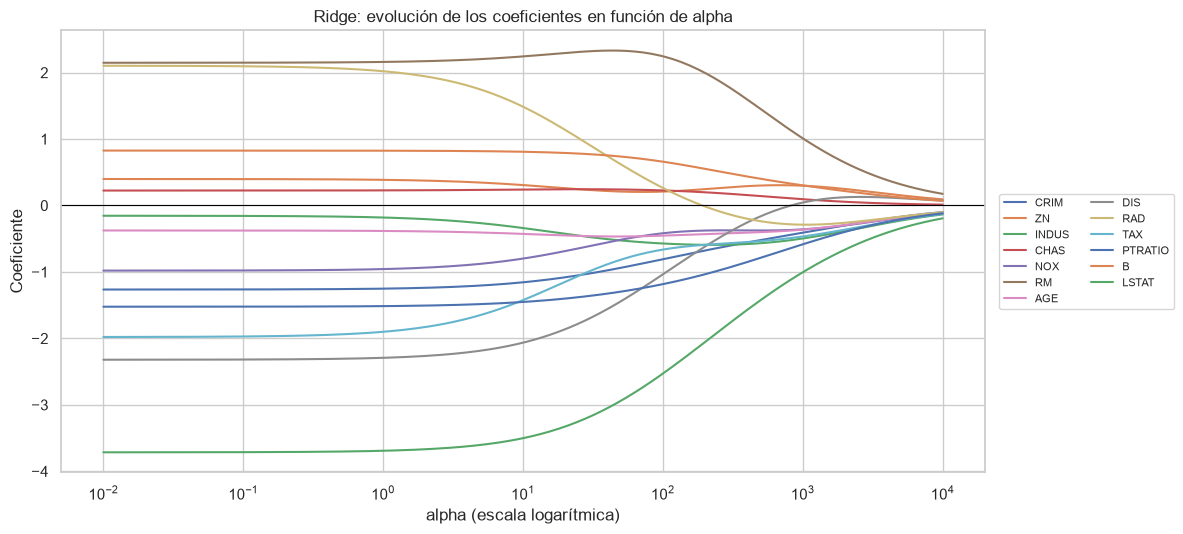

In [75]:
# Ridge sobre seis órdenes de magnitud de alpha
alphas_ridge = np.logspace(-2, 4, 200)
camino_ridge = camino_coeficientes(lambda a: Ridge(alpha=a), alphas_ridge)
graficar_camino(camino_ridge, "Ridge: evolución de los coeficientes en función de alpha")

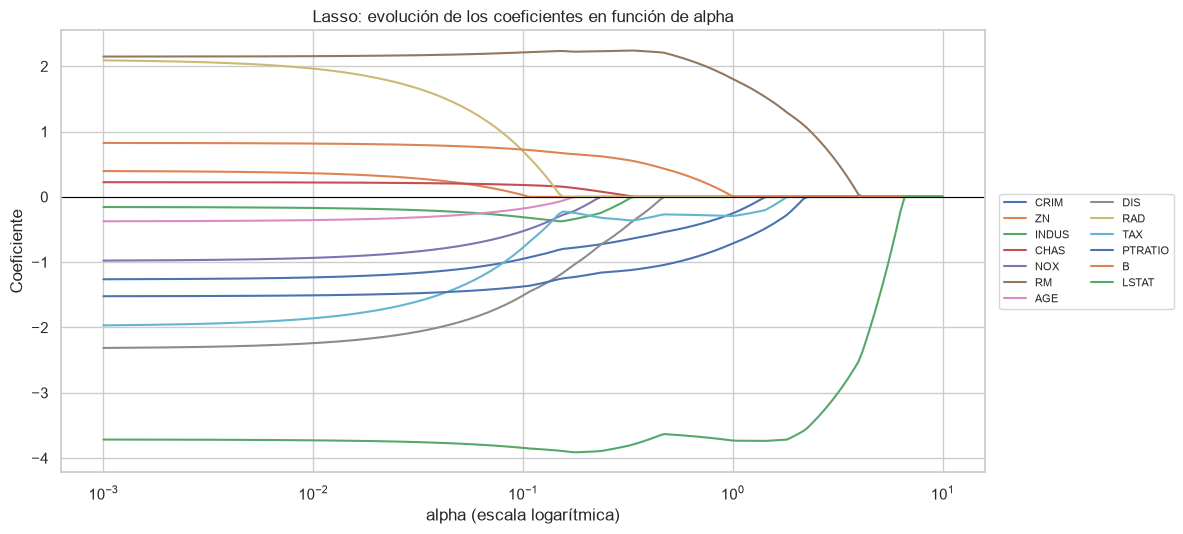

In [76]:
# Lasso sobre el rango donde pasa algo: de no penalizar casi nada a anularlo todo
alphas_lasso = np.logspace(-3, 1, 200)
camino_lasso = camino_coeficientes(lambda a: Lasso(alpha=a, max_iter=10000), alphas_lasso)
graficar_camino(camino_lasso, "Lasso: evolución de los coeficientes en función de alpha")

In [77]:
# Con Ridge ningún coeficiente llega nunca a cero; con Lasso desaparecen todos
print(f"Coeficientes exactamente nulos con Ridge (alpha hasta {alphas_ridge.max():.0f}): "
      f"{int((camino_ridge.abs() < 1e-10).sum().sum())}")
print(f"Coeficientes exactamente nulos con Lasso (alpha hasta {alphas_lasso.max():.0f}): "
      f"{int((camino_lasso.abs() < 1e-10).sum().sum())}")

Coeficientes exactamente nulos con Ridge (alpha hasta 10000): 0
Coeficientes exactamente nulos con Lasso (alpha hasta 10): 767


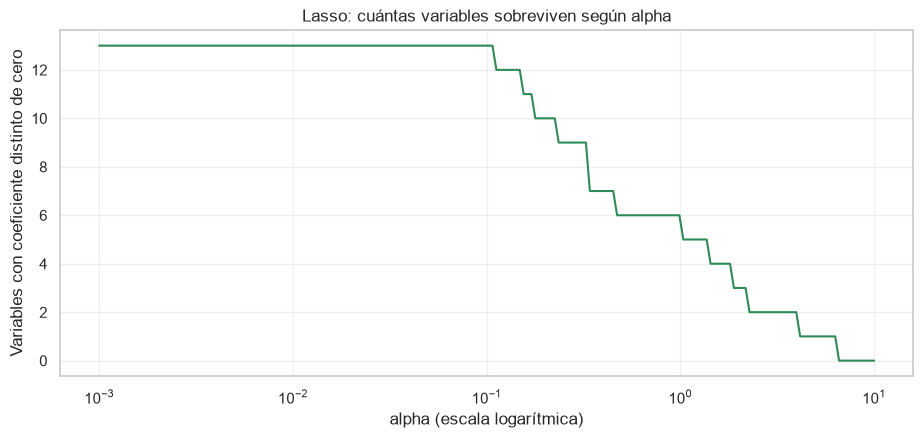

In [78]:
# Cuántas variables le quedan a Lasso según cuánto lo penalicemos
variables_vivas = (camino_lasso.abs() > 1e-10).sum(axis=1)

plt.figure(figsize=(11, 4.5))
plt.plot(variables_vivas.index, variables_vivas.values, color="seagreen")
plt.xscale("log")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Variables con coeficiente distinto de cero")
plt.title("Lasso: cuántas variables sobreviven según alpha")
plt.grid(alpha=0.3)
plt.show()

In [79]:
# El orden en que Lasso las va descartando
def alpha_de_muerte(columna):
    nulos = camino_lasso.index[camino_lasso[columna].abs() < 1e-10]
    return nulos.min() if len(nulos) else np.nan

orden_descarte = pd.Series({c: alpha_de_muerte(c) for c in camino_lasso.columns})
orden_descarte.sort_values().to_frame("alpha al que se anula").round(3)

,alpha al que se anula
ZN,0.112
RAD,0.155
AGE,0.178
NOX,0.235
CHAS,0.341
INDUS,0.341
DIS,0.471
B,1.035
CRIM,1.431
TAX,1.890


In [80]:
# En Ridge, RAD arranca positivo y termina negativo: buscamos dónde cambia de signo
negativos = camino_ridge.index[camino_ridge["RAD"] < 0]
print(f"Coeficiente de RAD sin penalizar:        {lineal.coef_[list(X_train_prep.columns).index('RAD')]:+.3f}")
print(f"Correlación de RAD con MEDV:             {X_train['RAD'].corr(y_train):+.3f}")
print(f"RAD cambia de signo a partir de alpha ≈  {negativos.min():.0f}")

Coeficiente de RAD sin penalizar:        +2.104
Correlación de RAD con MEDV:             -0.475
RAD cambia de signo a partir de alpha ≈  205


### Lectura de los caminos

**Los dos gráficos muestran exactamente la diferencia entre las dos penalizaciones.** En
Ridge todas las curvas se acercan al cero de forma suave y nunca lo tocan: sobre 200 valores
de `alpha` y 13 variables no hay **ni un solo** coeficiente exactamente nulo, ni siquiera
con `alpha = 10.000`. En Lasso, en cambio, las curvas llegan al cero, lo tocan y se quedan
ahí. Esa es toda la diferencia entre achicar y seleccionar, y se ve de un vistazo.

**El orden en que Lasso descarta las variables es informativo por sí solo.** Las primeras en
caer son `ZN` y `RAD`, y las últimas dos en quedar en pie son `RM` y `LSTAT`, que son
justamente las dos más correlacionadas con `MEDV`. Lasso está ordenando las variables por
cuánto aportan, y el orden coincide con lo que venimos viendo en todo el trabajo.

Dentro de ese orden hay dos detalles que nos llamaron la atención:

- **`RAD` cae segunda, `TAX` recién décima.** Eran nuestro par colineal (correlación 0,904),
  y Lasso los separa: se queda con uno y descarta el otro en cuanto puede. No es que `RAD`
  no sirva, es que con `TAX` adentro no agrega nada que justifique su costo.
- **`ZN` es la primera y `CHAS` la quinta.** Era la pregunta que nos veníamos haciendo desde
  el análisis descriptivo, cuando vimos que `CHAS` tenía una correlación de apenas 0,048.
  Confirmado: son de las que menos aportan. Dónde cae exactamente el corte depende del
  `alpha` que terminemos eligiendo, así que la respuesta definitiva queda para el ítem 5.

**Y hay algo en el camino de Ridge que cierra una historia que arrastramos desde el VIF.**
`RAD` tiene coeficiente +2,104 sin penalizar, pero su correlación con `MEDV` es **negativa**
(−0,475): era el cambio de signo que atribuimos a la colinealidad con `TAX`. En el gráfico
se ve cómo, a medida que sube `alpha`, ese coeficiente baja, cruza el cero cerca de
`alpha ≈ 205` y se queda del lado negativo.

O sea que **la regularización deshace el cambio de signo**. Al castigar los coeficientes
grandes, Ridge deja de permitir el arreglo de "`RAD` muy positivo compensado con `TAX` muy
negativo", que es un reparto que ajusta bien el entrenamiento pero que depende de la muestra
que nos tocó. Cuando esa compensación deja de ser gratis, `RAD` se acomoda del lado que
indica su relación real con el precio. Es la misma inestabilidad que medimos con el
remuestreo, vista desde otro ángulo.

### ¿Ridge estabiliza los coeficientes?

Cuando calculamos el VIF dejamos anotada una hipótesis: que Ridge no nos iba a mejorar mucho
la predicción, pero sí la **estabilidad** de los coeficientes, que era el problema real que
nos marcó la colinealidad en `RAD` y `TAX`. Las métricas de recién confirman la primera
mitad. Falta la segunda, y no se puede ver mirando un solo ajuste: la inestabilidad es
cuánto cambiarían los coeficientes si nos hubiera tocado otra muestra.

Para medirlo armamos 200 muestras distintas del conjunto de entrenamiento, sorteando filas
con reemplazo, y ajustamos los modelos en cada una. Si un coeficiente es estable, va a dar
parecido en las 200; si es inestable, va a saltar. El desvío estándar de esos 200 valores es
la medida directa de lo que el VIF estimaba de forma indirecta.

In [81]:
# Remuestreamos el entrenamiento 200 veces y vemos cuánto salta cada coeficiente
generador = np.random.default_rng(SEMILLA)
modelos = {"LinearRegression": LinearRegression(), "Ridge alpha=1": Ridge(alpha=1),
           "Ridge alpha=10": Ridge(alpha=10), "Ridge alpha=100": Ridge(alpha=100)}
acumulado = {nombre: [] for nombre in modelos}

for _ in range(200):
    filas = generador.integers(0, len(X_train_prep), len(X_train_prep))
    X_muestra, y_muestra = X_train_prep.iloc[filas], y_train.iloc[filas]
    for nombre, modelo in modelos.items():
        acumulado[nombre].append(modelo.fit(X_muestra, y_muestra).coef_)

In [82]:
# Desvío estándar de cada coeficiente a lo largo de las 200 muestras
estabilidad = pd.DataFrame({nombre: np.std(np.array(v), axis=0) for nombre, v in acumulado.items()},
                           index=X_train_prep.columns)
estabilidad["VIF"] = vif["VIF"]
estabilidad.sort_values("VIF", ascending=False).round(3)

,LinearRegression,Ridge alpha=1,Ridge alpha=10,Ridge alpha=100,VIF
TAX,0.512,0.489,0.357,0.136,8.858
RAD,0.483,0.462,0.344,0.139,7.088
NOX,0.371,0.363,0.310,0.144,4.617
INDUS,0.343,0.337,0.293,0.159,4.187
DIS,0.417,0.408,0.345,0.161,4.000
LSTAT,0.662,0.651,0.572,0.260,3.362
AGE,0.454,0.446,0.385,0.188,3.179
ZN,0.306,0.301,0.272,0.180,2.323
RM,0.572,0.567,0.521,0.323,2.076
PTRATIO,0.218,0.215,0.198,0.147,1.765


In [83]:
# Cuánto se redujo la inestabilidad total al regularizar
print("Suma de los desvíos de los 13 coeficientes:")
for nombre in modelos:
    total = estabilidad[nombre].sum()
    print(f"  {nombre:20s} {total:.2f}   ({total / estabilidad['LinearRegression'].sum() - 1:+.0%})")

Suma de los desvíos de los 13 coeficientes:
  LinearRegression     4.99   (+0%)
  Ridge alpha=1        4.88   (-2%)
  Ridge alpha=10       4.17   (-16%)
  Ridge alpha=100      2.23   (-55%)


### Lectura de la estabilidad

**La hipótesis se cumple.** Con `alpha = 100` la suma de los desvíos baja de 4,99 a 2,23, o
sea que los coeficientes se vuelven **menos de la mitad de volátiles** de lo que eran sin
regularizar. Y no baja parejo: la tabla está ordenada por VIF y las dos primeras filas son
las que más ganan.

`TAX`, con el VIF más alto (8,86), pasa de un desvío de 0,512 a 0,136: una reducción del
73%. `RAD`, el segundo (7,09), va de 0,483 a 0,139, un 71% menos. En el otro extremo, `CHAS`
y `B`, que tienen los VIF más bajos del conjunto (1,05 y 1,26), apenas mejoran un 30%. La
regularización le pega más fuerte justo donde el VIF había señalado el problema, que es
lo que predecía la teoría: Ridge reparte el peso entre las variables
correlacionadas en vez de dejar que el ajuste elija un reparto arbitrario, y eso hace que la
muestra puntual que nos tocó deje de determinar el resultado.

Con `alpha = 1` la mejora es mínima (−2%), lo cual encaja con que las métricas y los
coeficientes tampoco se movían: esa penalización es demasiado chica para hacer algo.

Eso sí, esto es un **intercambio, no algo gratis**. Los coeficientes se vuelven
más estables porque se hacen más chicos y más parecidos entre sí, y eso los aleja del valor
que minimiza el error sobre entrenamiento. Es el compromiso sesgo-varianza en su forma más
concreta: bajamos varianza pagando con sesgo. Que convenga o no depende de para qué
queremos el modelo. Si lo único que nos importa es predecir, acá no gana nada. Si además
queremos leer los coeficientes y decir algo sobre qué encarece una vivienda, un coeficiente
estable vale bastante más que uno que cambia de signo según la muestra.

In [84]:
# Guardamos los tres para la comparación final del ítem 6
resultados["Ridge (alpha=1)"] = metricas(y_test, ridge.predict(X_test_prep))
resultados["Lasso (alpha=1)"] = metricas(y_test, lasso.predict(X_test_prep))
resultados["Elastic Net (alpha=1)"] = metricas(y_test, elastic.predict(X_test_prep))
pd.DataFrame(resultados).round(4)

,LinearRegression,GD por lotes,GD estocástico,GD mini-batch,Ridge (alpha=1),Lasso (alpha=1),Elastic Net (alpha=1)
R²,0.769,0.7690,0.7645,0.7679,0.7694,0.7375,0.7342
RMSE,3.878,3.8779,3.9163,3.8872,3.8750,4.1344,4.1599
MAE,2.850,2.8497,2.8496,2.8498,2.8465,3.2466,3.2084


### Cierre del ítem

Con `alpha = 1` ninguno de los tres mejora a `LinearRegression` en predicción: Ridge empata
y los otros dos pierden. Pero ese `alpha` lo tomamos prestado del valor por defecto de
scikit-learn, sin ninguna razón que tenga que ver con nuestros datos, así que la conclusión
todavía no está cerrada. El barrido de `alpha` es el ítem que sigue, y ahí vamos a poder
decir si el problema es la regularización en sí o simplemente que la dosis estaba mal
elegida.